# Stage 1 · WP3: Open Models Knowledge Graph

| | |
|---|---|
| **Work package** | WP3: knowledge graph construction, analysis and storage |
| **Track** | Open models |
| **Input** | WP2 handover (entities, relations with evidence sentences, co-occurrence, schema), WP1 lexicon and article table |
| **Output** | Typed relations with evidence, three graph views, metrics, figures, schema and data dictionary for Stage 3 |

This notebook turns the entities and relations extracted in WP2 into a topic-focused knowledge graph. It refines
the extracted relations for graph use, measures their quality with a human review, and then builds, analyses,
visualises and stores the graph.

| Stage 1 requirement (Knowledge Graph Construction) | Section |
|---|---|
| Define a compact topic-specific schema before graph construction | 7 |
| Nodes represent entities, edges represent co-mentions or extracted relations | 8 |
| Network metrics (centrality, clustering) for influential entities and emerging relationships | 9–12 |
| Visualise the graph with NetworkX | 13 |
| Key insights with evidence | 14 |
| Store the graph and its schema for Stage 3 | 16–17 |

**Workflow**

```
WP2 handover (read only)
  -> 2. validate the handover
  -> 3-5. refine entities and relations, assign quality tiers, add model-level relations
  -> 6. human review and error-driven refinement
  -> 7-8. compact schema and graph views
  -> 9-12. structure, centrality, communities, temporal analysis
  -> 13-15. figures, findings with evidence, limitations
  -> 16-18. export, Stage 3 retrieval check, requirement check
```

## 1. Setup

All inputs are read from disk and none of them is modified. The notebook runs from the team repository
(`stage1/work_packages/`) or from a copy with the same folders; each input is looked up in both layouts.

| input | team repository | content |
|---|---|---|
| WP2 handover | `artifacts/stage1_wp2/` | entities, relations, evidence sentences, co-occurrence, schema |
| WP1 lexicon | `artifacts/stage1_wp1/lexicon/open_models_lexicon.json` | model families and their developers |
| WP1 article table (optional) | `data/processed/open_models_core.parquet` | scope check, article titles and URLs |
| human review | `artifacts/stage1_wp3/review/` | review of the Tier B sample, the supplementary sample and the relations behind the findings |
| compact schema, helper code | `config/wp3_compact_schema.json`, `src/` | entity and predicate grouping, graph metrics, Stage 3 retriever |

Large outputs are written to `outputs/stage1_wp3_knowledge_graph/`; the schema, data dictionary, summary tables
and figures are also written to `artifacts/stage1_wp3/final/`.

In [1]:
from datetime import datetime, timezone
from pathlib import Path
import hashlib
import json
import re
import sys
import unicodedata

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config" / "wp3_compact_schema.json").exists())
sys.path.insert(0, str(ROOT / "src"))

from stage3_graph_rag import GraphEvidenceRetriever
from wp3_knowledge_graph.pipeline import (
    build_relation_type_summary,
    calculate_node_metrics,
    calculate_relation_type_metrics,
    collapse_relations,
    detect_cooccurrence_communities,
    graph_summary,
)

def first_existing(*candidates):
    # The first candidate that exists (team repository layout first); the first candidate if none exists
    return next((p for p in candidates if p.exists()), candidates[0])

REVIEW_DIRS = [ROOT / "artifacts" / "stage1_wp3" / "review",
               ROOT / "artifacts" / "stage1_wp3" / "evaluation" / "relation_correction"]
WP2_INPUT_DIR = first_existing(ROOT / "artifacts" / "stage1_wp2" / "nodes.csv",
                               ROOT / "outputs" / "stage1_wp2_open_models_official_20261007" / "nodes.csv").parent
LEXICON_PATH = ROOT / "artifacts" / "stage1_wp1" / "lexicon" / "open_models_lexicon.json"
WP1_CORE_PATH = first_existing(ROOT / "data" / "processed" / "open_models_core.parquet",
                               ROOT / "dataset" / "processed" / "open_models_core.parquet")  # optional
REVIEW_PATH = first_existing(*[d / "relation_review_corrected_seed2026.xlsx" for d in REVIEW_DIRS])
SUPPLEMENT_REVIEW_PATH = first_existing(*[d / "relation_review_supplement_seed2026.xlsx" for d in REVIEW_DIRS])
INSIGHT_CHECK_PATH = first_existing(*[d / "insight_relation_check.csv" for d in REVIEW_DIRS])
AI_PRESCREEN_PATH = first_existing(ROOT / "artifacts" / "stage1_wp3" / "review" / "relation_review_claude_draft.csv",
                                   ROOT / "artifacts" / "stage1_wp2" / "evaluation" / "ai_prescreen"
                                   / "relation_review_claude_draft.csv")  # optional
COMPACT_SCHEMA_PATH = ROOT / "config" / "wp3_compact_schema.json"
OUTPUT_DIR = ROOT / "outputs" / "stage1_wp3_knowledge_graph"
ARTIFACT_DIR = ROOT / "artifacts" / "stage1_wp3" / "final"
FIGURE_DIR = ARTIFACT_DIR / "figures"
for directory in [OUTPUT_DIR / "correction", FIGURE_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

MIN_COOCCURRENCE_DOCUMENTS = 2    # co-occurrence edges: minimum number of articles (Section 8)
DRAW_COOCCURRENCE_DOCUMENTS = 5   # community figure only
SEED = 42
PERIODS = {"P1 (2024-09 to 2025-08)": ("2024-09-01", "2025-08-31"),
           "P2 (2025-09 to 2026-08)": ("2025-09-01", "2026-08-31")}

for required_path in [WP2_INPUT_DIR / "nodes.csv", LEXICON_PATH, REVIEW_PATH, SUPPLEMENT_REVIEW_PATH,
                      INSIGHT_CHECK_PATH, COMPACT_SCHEMA_PATH]:
    assert required_path.exists(), f"Missing input: {required_path}"
print(f"Repository root: {ROOT}")
print(f"WP2 handover: {WP2_INPUT_DIR.relative_to(ROOT)} | review files: {REVIEW_PATH.parent.relative_to(ROOT)}")

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

def save_figure(fig, filename):
    # The WP3 pipeline module uses the non-interactive Agg backend, so the saved PNG is displayed.
    path = FIGURE_DIR / filename
    fig.savefig(path, dpi=160, bbox_inches="tight")
    plt.close(fig)
    display(Image(filename=str(path)))

def pretty(label):
    return str(label).replace("_", " ")

Repository root: /Users/jihyeon/projects/others/CLT_personal/2026-09-CLT-computational_language
WP2 handover: outputs/stage1_wp2_open_models_official_20261007 | review files: artifacts/stage1_wp3/evaluation/relation_correction


## 2. WP2 handover: load and validate

Before building the graph, the handover must be complete and internally linked:

- all expected files exist;
- node IDs and sentence IDs (`doc_id` + `sentence_id`) are unique;
- every relation evidence sentence exists in `sentences.csv` and every relation endpoint exists in `nodes.csv`;
- the WP2 articles are exactly the WP1 Open Models core articles (checked when the WP1 table is available).

In [2]:
WP2_FILES = ["nodes.csv", "nodes_quarterly.csv", "entity_mentions.csv", "sentences.csv", "edges_relations.csv",
             "relations_evidence.csv", "edges_cooccurrence.csv", "schema.json"]
missing_files = [name for name in WP2_FILES if not (WP2_INPUT_DIR / name).exists()]
assert not missing_files, f"Missing WP2 files: {missing_files}"

nodes = pd.read_csv(WP2_INPUT_DIR / "nodes.csv", keep_default_na=False, na_values=[""])
edges = pd.read_csv(WP2_INPUT_DIR / "edges_relations.csv")
evidence_all = pd.read_csv(WP2_INPUT_DIR / "relations_evidence.csv")
cooccurrence_wp2 = pd.read_csv(WP2_INPUT_DIR / "edges_cooccurrence.csv")
sentences = pd.read_csv(WP2_INPUT_DIR / "sentences.csv")
schema = json.loads((WP2_INPUT_DIR / "schema.json").read_text(encoding="utf-8"))
lexicon = json.loads(LEXICON_PATH.read_text(encoding="utf-8"))
compact_schema = json.loads(COMPACT_SCHEMA_PATH.read_text(encoding="utf-8"))

evidence = evidence_all[evidence_all["source"] == "glirel"].copy()
evidence["sentence_id"] = evidence["sentence_id"].astype(int)
lexicon_edges = edges[edges["source"] == "wp1_lexicon"].copy()
REL_TYPES = schema["edges"]["relation"]["types"]

sentence_keys = set(zip(sentences["doc_id"], sentences["sentence_id"]))
if WP1_CORE_PATH.exists():
    wp1_doc_ids = set(pd.read_parquet(WP1_CORE_PATH, columns=["doc_id"])["doc_id"])
    lineage = ("PASS" if wp1_doc_ids == set(sentences["doc_id"]) else "FAIL", f"{len(wp1_doc_ids):,} WP1 articles")
else:
    lineage = ("SKIP", "WP1 table not available")

input_checks = pd.DataFrame(
    [
        ("WP2 files present", "PASS", f"{len(WP2_FILES)} files"),
        ("Node IDs unique", "PASS" if nodes["entity_id"].is_unique else "FAIL", f"{len(nodes):,} nodes"),
        ("Sentence IDs unique", "PASS" if len(sentence_keys) == len(sentences) else "FAIL",
         f"{len(sentences):,} sentences in {sentences['doc_id'].nunique():,} articles"),
        ("Evidence sentences exist", "PASS" if set(zip(evidence["doc_id"], evidence["sentence_id"])) <= sentence_keys
         else "FAIL", f"{len(evidence):,} GLiREL evidence rows"),
        ("Relation endpoints exist",
         "PASS" if (set(evidence_all["head_id"]) | set(evidence_all["tail_id"])) <= set(nodes["entity_id"]) else "FAIL",
         f"{(edges['source'] == 'glirel').sum():,} GLiREL triples, {len(lexicon_edges)} lexicon triples"),
        ("WP2 articles = WP1 core articles", *lineage),
        ("WP2 schema", "INFO", f"{len(schema['node']['entity_types'])} entity types, {len(REL_TYPES)} relation types"),
    ],
    columns=["check", "result", "detail"],
)
display(input_checks)
assert not input_checks["result"].eq("FAIL").any()

,check,result,detail
0,WP2 files present,PASS,8 files
1,Node IDs unique,PASS,"54,597 nodes"
2,Sentence IDs unique,PASS,"99,438 sentences in 1,210 articles"
3,Evidence sentences exist,PASS,"30,560 GLiREL evidence rows"
4,Relation endpoints exist,PASS,"22,957 GLiREL triples, 35 lexicon triples"
5,WP2 articles = WP1 core articles,PASS,"1,210 WP1 articles"
6,WP2 schema,INFO,"20 entity types, 36 relation types"


## 3. From extracted relations to a knowledge graph

WP2 is designed for recall: a broad schema (20 entity types, 36 relation types) and zero-shot extraction keep as
many candidate relations as possible, each with its evidence sentences. A knowledge graph that is analysed and
used to answer questions in Stage 3 needs higher precision, so WP3 adds a refinement step on top of the WP2
output. The WP2 files themselves are not changed.

The refinement was developed in two rounds. The extracted relations were first screened with AI, which showed
that most issues arise at the entity level rather than in the relation classifier. Rules for these issues were
applied (Section 4), and a sample of 90 of the remaining relations was then reviewed by people (Section 6).
The issues found in the first round:

- **generic phrases** such as `model`, `company` or `AI models` appear as relation endpoints;
- **entity links in context**: family-level name matching, which is the right choice for counting mentions, also
  matches product names that contain a family name (*Llama Nemotron*, *Llama Stack*); in sentences that list
  several names, a relation can attach to a neighbouring name;
- **name variants and types**: the same organisation can appear under several names or types (`Ai2` and
  `Allen Institute for AI`; `Alibaba` as a place).

A confidence threshold would remove correct and incorrect relations alike, so each issue gets a targeted rule.

## 4. Relation refinement

The refinement maps WP2 IDs to corrected nodes, flags evidence sentences and relations with a reason, and assigns
every relation to a quality tier. Nothing is deleted: excluded items keep their reason in the exported correction
tables.

### 4.1 Nodes

**Name variants.** Nodes whose names differ only by casing, punctuation or an encoding artefact (`OpenAIâ`) are
merged into the most frequent node of the same type group.

In [3]:
TYPE_GROUP = {"FOUNDATION_MODEL": "model", "AI_MODEL": "model", "COMPANY": "org", "ORG": "org"}

def name_key(name):
    s = unicodedata.normalize("NFKC", str(name))
    s = re.sub(r"â\S*$", "", s)                                  # encoding artefact: OpenAIâ -> OpenAI
    s = re.sub(r"(?<=[A-Za-z0-9])[가-힣]+$", "", s)    # Korean particle after a Latin name
    return re.sub(r"[^0-9a-z]+", " ", s.lower()).strip()

nodes["key"] = nodes["entity"].map(name_key)
nodes["group"] = nodes["entity_type"].map(TYPE_GROUP).fillna(nodes["entity_type"])
nodes["is_lexicon"] = nodes["canonical_id"].notna()

variant_rows = []
for (key, group), g in nodes[nodes["key"] != ""].groupby(["key", "group"]):
    if len(g) < 2:
        continue
    keep = g.sort_values(["is_lexicon", "mentions"], ascending=False).iloc[0]
    for _, r in g[g["entity_id"] != keep["entity_id"]].iterrows():
        variant_rows.append({"from_id": r["entity_id"], "from_name": r["entity"], "to_id": keep["entity_id"],
                             "to_name": keep["entity"], "reason": "name_variant"})
name_variants = pd.DataFrame(variant_rows)
print(f"Name variants merged: {len(name_variants):,}")
display(name_variants.merge(nodes[["entity_id", "mentions"]], left_on="from_id", right_on="entity_id")
        .sort_values("mentions", ascending=False).head(8)[["from_name", "to_name", "mentions"]])

Name variants merged: 375


,from_name,to_name,mentions
207,llama,Llama,24
356,vision language models,vision-language models,23
77,closed-source,closed source,14
138,gemma,Gemma,14
252,open source community,open-source community,13
188,instruction-following,instruction following,13
266,open-source software,open source software,12
294,Retrieval Augmented Generation,retrieval-augmented generation,12


**Curated corrections.** Three small tables hold the decisions that need domain knowledge:

- `ALIAS_MAP`: two IDs refer to the same entity (legal names, spelling variants, renamed organisations) and are merged;
- `NODE_OVERRIDES`: corrected name or type of a merged node;
- `DEVELOPER_EQUIVALENTS`: organisations that are not the same entity but are acceptable as the developer of a WP1
  model family (e.g. Google DeepMind for Gemma). They are only used for the developer check below.

Parent companies and their research units (Google and Google DeepMind, Microsoft and Microsoft Research) stay
separate nodes; relations such as `Google DeepMind -> acquired by -> Google` would otherwise become self-relations.

In [4]:
ALIAS_MAP = [  # from_id, to_id, note
    ("org:deepseek_2", "org:deepseek", "lexicon developer node duplicates the DeepSeek company"),
    ("place:alibaba", "org:alibaba", "Alibaba typed as a place"),
    ("org:alibaba_group", "org:alibaba", "same company"),
    ("org:alibaba_group_holding_limited", "org:alibaba", "same company"),
    ("org:alibaba_groupshares", "org:alibaba", "tokenisation artefact"),
    ("model:tii", "org:technology_innovation_institute", "TII typed as a model"),
    ("model:stability_ai", "org:stability_ai", "Stability AI typed as a model"),
    ("org:stability", "org:stability_ai", "same company"),
    ("org:moonshot", "org:moonshot_ai", "Moonshot = MoonShot AI"),
    ("org:z_ai", "org:zhipu_ai_z_ai", "Z.ai = Zhipu AI"),
    ("org:allen_institute_for_ai", "org:ai2", "Ai2 = Allen Institute for AI"),
    ("org:allen_institute_for_artificial_intelligence", "org:ai2", "Ai2 = Allen Institute for AI"),
    ("technology:model_context_protocol", "standard:mcp", "MCP = Model Context Protocol"),
    ("org:fundamental_artificial_intelligence_research_unit", "org:fair", "FAIR = Fundamental AI Research"),
    ("org:nous", "org:nous_research", "same company"),
    ("org:nousresearch", "org:nous_research", "same company"),
    ("org:cohere_for_ai", "org:cohere_labs", "Cohere For AI was renamed Cohere Labs"),
    ("org:cohere_lab", "org:cohere_labs", "same lab"),
    ("org:black_forest_labs", "org:black_forest_labs_2", "same company (lexicon developer node)"),
    ("person:anthropic_claude", "model:claude", "Claude typed as a person"),
    ("platform:meta_platforms", "org:meta", "Meta Platforms (legal name) typed as a platform"),
    ("org:meta_platforms_inc", "org:meta", "legal name of Meta"),
    ("org:meta_platforms_inc_2", "org:meta", "legal name of Meta"),
    ("org:meta_platforms_inc_3", "org:meta", "legal name of Meta"),
    ("org:deepmind", "org:google_deepmind", "DeepMind was renamed Google DeepMind in 2023"),
    ("org:deep_seek", "org:deepseek", "spelling variant"),
    ("org:google_llc", "org:google", "legal name of Google"),
    ("org:alphabet_inc", "org:alphabet", "legal name of Alphabet"),
    ("org:alibaba_group_holding", "org:alibaba", "same company"),
    ("org:nvidia_co", "org:nvidia", "same company"),
    ("org:cognition_ai", "org:cognition", "same company"),
    ("org:perplexity_ai", "org:perplexity", "same company"),
    ("org:rand_corporation", "org:rand", "same organisation"),
    ("org:red_hat_inc_2", "org:red_hat", "legal name of Red Hat"),
    ("org:redhat", "org:red_hat", "spelling variant"),
    ("org:liquid", "org:liquid_ai", "Liquid = Liquid AI"),
    ("org:ant", "org:ant_group", "Ant = Ant Group"),
    ("org:thinking_machines", "org:thinking_machines_lab", "Thinking Machines = Thinking Machines Lab"),
    ("org:counterpoint", "org:counterpoint_research", "Counterpoint = Counterpoint Research"),
    ("org:hugging_face", "technology:hugging_face", "lexicon developer node duplicates Hugging Face"),
]
NODE_OVERRIDES = [  # entity_id, entity, entity_type, note
    ("org:alibaba", "Alibaba", "COMPANY", "node existed only as the variant 'Alibabaâ'"),
    ("org:stability_ai", "Stability AI", "COMPANY", "new ID for the corrected type"),
    ("org:technology_innovation_institute", "Technology Innovation Institute (TII)", "ORG", "lexicon developer of Falcon"),
    ("org:black_forest_labs_2", "Black Forest Labs", "COMPANY", ""),
    ("person:devin", "Devin", "AI_MODEL", "Cognition coding agent, not a person"),
    ("technology:hugging_face", "Hugging Face", "TECHNOLOGY", "display name was the ID-like 'hugging_face'"),
]
DEVELOPER_EQUIVALENTS = {  # lexicon developer -> organisations also accepted as developer of its families
    "org:google": ["org:google_deepmind", "org:deepmind", "org:google_research"],
    "org:alibaba": ["platform:alibaba_cloud", "org:alibaba_cloud_model_studio"],
    "org:meta": ["org:fair", "model:meta_ai"],
    "org:nvidia": ["org:nvidia_research"],
    "org:cohere": ["org:cohere_labs"],
    "org:g42_inception": ["org:g42", "org:inception"],
    "org:mistral_ai": ["model:mistral"],
    "org:minimax": ["product:minimax"],
}

# Resolve every WP2 ID to its corrected ID (name variants first, then aliases; chains are followed)
merge_map = dict(zip(name_variants["from_id"], name_variants["to_id"]))
merge_map.update({a: b for a, b, _ in ALIAS_MAP})

def resolve(entity_id):
    seen = set()
    while entity_id in merge_map and entity_id not in seen:
        seen.add(entity_id)
        entity_id = merge_map[entity_id]
    return entity_id

nodes["final_id"] = nodes["entity_id"].map(resolve)
merged = (nodes.groupby("final_id")
          .agg(merged_ids=("entity_id", lambda x: " | ".join(sorted(x))), mentions=("mentions", "sum"),
               n_docs=("n_docs", "max"), first_seen=("first_seen", "min"), last_seen=("last_seen", "max"))
          .reset_index().rename(columns={"final_id": "entity_id"}))
base = nodes.set_index("entity_id")[["entity", "entity_type", "canonical_id", "developer", "model_versions"]]
nodes_corrected = merged.join(base, on="entity_id")
for entity_id, name, entity_type, _ in NODE_OVERRIDES:
    if entity_id not in set(nodes_corrected["entity_id"]):
        nodes_corrected = pd.concat(
            [nodes_corrected, pd.DataFrame([{"entity_id": entity_id, "merged_ids": entity_id, "mentions": 0}])],
            ignore_index=True)
    nodes_corrected.loc[nodes_corrected["entity_id"] == entity_id, ["entity", "entity_type"]] = [name, entity_type]
print(f"Nodes: {len(nodes):,} -> {len(nodes_corrected):,} after merging")

Nodes: 54,597 -> 54,188 after merging


**Generic nodes.** For named-entity types (models, organisations, people, products, platforms, hardware,
technologies, ...), a node is *generic* if its name contains no proper-name token. A token counts as a proper name
if it contains an upper-case letter and is not a class word such as *AI*, *LLM* or *GPU*, or if it mixes letters
and digits (`o3`, `R1`). Concept types (`CAPABILITY`, `ARCHITECTURE`, `MODEL_SPEC`, `OPENNESS_CONCEPT`) are
lower-case by nature (*reasoning*, *mixture of experts*), so only vague words such as *capabilities* are generic
there. WP1 lexicon entities and named normalisations (`united_states`, `hugging_face`) are never generic. Generic
nodes are kept in the node table but are not used as relation or co-occurrence endpoints.

In [5]:
CLASS_WORDS = {"ai", "genai", "llm", "llms", "slm", "slms", "vlm", "vlms", "ml", "gpu", "gpus", "cpu", "cpus",
               "vm", "vms", "api", "apis", "app", "apps", "big", "tech", "ceo", "cto", "cfo", "coo", "vl", "us",
               "rl", "rlhf", "rag", "nlp", "ocr", "vr", "ar", "xr",                       # technique acronyms
               "the", "this", "these", "those", "its", "our", "their", "other", "new"}   # determiners
CONCEPT_TYPES = {"CAPABILITY", "ARCHITECTURE", "MODEL_SPEC", "OPENNESS_CONCEPT"}
VAGUE_WORDS = {"capability", "capabilities", "ability", "abilities", "feature", "features", "framework",
               "frameworks", "architecture", "architectures", "model", "models", "technology", "technologies",
               "performance"}
NOT_GENERIC = {"watsonx"}
NORMS = {norm for _, norm in lexicon["phrase_normalisation"]}
CLASS_NORMS = {"llm", "slm", "ai", "generative_ai", "foundation_model", "reasoning_model", "open_source", "open_weight"}

def is_generic(name, entity_type, is_lexicon):
    name = str(name)
    if is_lexicon or name.lower() in NOT_GENERIC:
        return False
    if entity_type in CONCEPT_TYPES:
        words = name.lower().split()
        return bool(words) and all(w in VAGUE_WORDS for w in words)
    if name in NORMS:
        return name in CLASS_NORMS
    tokens = re.findall(r"[A-Za-z0-9][A-Za-z0-9.+'\-]*", name)
    if not tokens:  # non-Latin names are kept
        return False
    def proper(token):
        if re.search(r"[A-Za-z]", token) and re.search(r"\d", token):
            return True
        return (any(c.isupper() for c in token) and token.lower() not in CLASS_WORDS
                and token.lower().rstrip("s") not in CLASS_WORDS)
    return not any(proper(token) for token in tokens)

nodes_corrected["is_generic"] = [is_generic(n, t, pd.notna(c)) for n, t, c in
                                 zip(nodes_corrected["entity"], nodes_corrected["entity_type"],
                                     nodes_corrected["canonical_id"])]
generic_ids = set(nodes_corrected.loc[nodes_corrected["is_generic"], "entity_id"])
print(f"Generic nodes: {len(generic_ids):,} of {len(nodes_corrected):,}")
display(nodes_corrected[nodes_corrected["is_generic"]].nlargest(10, "mentions")[["entity", "entity_type", "mentions"]])

Generic nodes: 20,798 of 54,188


,entity,entity_type,mentions
49321,AI,TECHNOLOGY,7631
23771,model,AI_MODEL,3283
23553,llm,AI_MODEL,2404
13392,data,DATASET,970
28546,company,COMPANY,893
36502,developers,PERSON,821
23795,models,AI_MODEL,763
49542,API,TECHNOLOGY,758
20925,open_source,LICENSE,657
18517,GPU,HARDWARE,602


### 4.2 Evidence sentences

1. Head and tail are mapped to the corrected nodes; relations that become self-relations are dropped.
2. **Family span**: a WP1 model family is not linked in a sentence where it only occurs inside another product
   name (*Llama Nemotron*, *Llama Stack*, *LlamaCon*). The lexicon pattern is re-applied after removing these names.
3. `competes with` is symmetric, so head and tail are put in a fixed order.
4. Schema type constraints are re-checked with the corrected types.

In [6]:
MATCH_MAP = str.maketrans({"‐": "-", "‑": "-", "‒": "-", "–": "-", "−": "-", "‘": "'", "’": "'", "“": '"', "”": '"'})
FAMILY_SPAN_RX = {f"model:{fid}": re.compile(f["rx"]) for fid, f in lexicon["families"].items()}
FAMILY_SPAN_EXCEPTIONS = {  # family node -> product names that contain the family name
    "model:llama": re.compile(r"\bLlama[\w.\- ]{0,15}?(?:Nemotron|Stack)\b|\bLlamaCon\b"),
}
SYMMETRIC = {"competes with"}
node_info = nodes_corrected.set_index("entity_id")

ev = evidence.copy()
ev["orig_head_id"], ev["orig_tail_id"] = ev["head_id"], ev["tail_id"]
ev["head_id"] = ev["head_id"].map(resolve)
ev["tail_id"] = ev["tail_id"].map(resolve)
ev["evidence_status"] = "ok"
ev.loc[ev["head_id"] == ev["tail_id"], "evidence_status"] = "self_relation_after_merge"

def family_span_only(family_id, text):
    exceptions = FAMILY_SPAN_EXCEPTIONS.get(family_id)
    if exceptions is None:
        return False
    view = str(text).translate(MATCH_MAP)
    return bool(exceptions.search(view)) and not FAMILY_SPAN_RX[family_id].search(exceptions.sub(" ", view))

for side in ("head_id", "tail_id"):
    mask = ev[side].isin(FAMILY_SPAN_EXCEPTIONS) & (ev["evidence_status"] == "ok")
    hit = [family_span_only(f, t) for f, t in zip(ev.loc[mask, side], ev.loc[mask, "sentence_text"])]
    ev.loc[mask[mask].index[hit], "evidence_status"] = "family_span"

swap = ev["relation"].isin(SYMMETRIC) & (ev["head_id"] > ev["tail_id"])
ev.loc[swap, ["head_id", "tail_id", "orig_head_id", "orig_tail_id"]] = \
    ev.loc[swap, ["tail_id", "head_id", "orig_tail_id", "orig_head_id"]].values

for side in ("head", "tail"):
    ev[side] = ev[f"{side}_id"].map(node_info["entity"])
    ev[f"{side}_type"] = ev[f"{side}_id"].map(node_info["entity_type"])

def type_ok(relation, head_type, tail_type):
    spec = REL_TYPES.get(relation)
    if spec is None:
        return False
    forward = head_type in spec["head_types"] and tail_type in spec["tail_types"]
    backward = tail_type in spec["head_types"] and head_type in spec["tail_types"]
    return forward or (relation in SYMMETRIC and backward)

ev["type_valid_corrected"] = [type_ok(r, h, t) for r, h, t in zip(ev["relation"], ev["head_type"], ev["tail_type"])]
ev["sentence_key"] = ev["sentence_text"].fillna("").map(lambda s: re.sub(r"\W+", " ", s.lower()).strip())
display(ev["evidence_status"].value_counts().rename_axis("evidence status").reset_index(name="sentences"))

,evidence status,sentences
0,ok,30448
1,family_span,110
2,self_relation_after_merge,2


### 4.3 Relation checks and quality tiers

Evidence rows with status `ok` are aggregated per `(head, relation, tail)`. Support is counted on **distinct
sentence texts**, because syndicated articles repeat the same sentence. Each relation is then checked:

| check | rule |
|---|---|
| `type_invalid` | head and tail types do not satisfy the schema after correction |
| `generic_node` | head or tail is a generic node |
| `conflicts_lexicon_developer` | a WP1 model family is `developed/released/announced by` an organisation that is not its WP1 developer (or an accepted equivalent) |
| `own_product_or_parent` | `competes with` / `outperforms` between an artefact and its own developer or parent company |
| `reverse_duplicate` | the same directional relation exists in both directions; the less supported direction is excluded |

| tier | meaning | used in the graph |
|---|---|---|
| A | WP1 lexicon model family -> developer (curated, no article sentence) | yes |
| B | passes all checks, at least 2 distinct evidence sentences | yes |
| C | passes all checks, 1 evidence sentence | no |
| X | excluded by a check | no |

In [7]:
ok = ev[ev["evidence_status"] == "ok"]
relations = (ok.groupby(["head_id", "relation", "tail_id"])
             .agg(head=("head", "first"), head_type=("head_type", "first"), tail=("tail", "first"),
                  tail_type=("tail_type", "first"), type_valid=("type_valid_corrected", "first"),
                  n_sentences=("sentence_key", "size"), n_distinct_sentences=("sentence_key", "nunique"),
                  n_docs=("doc_id", "nunique"), mean_score=("score", "mean"),
                  first_seen=("date", "min"), last_seen=("date", "max"),
                  orig_head_ids=("orig_head_id", lambda x: " | ".join(sorted(set(x)))),
                  orig_tail_ids=("orig_tail_id", lambda x: " | ".join(sorted(set(x)))))
             .reset_index())
relations["source"] = "glirel"
relations["mean_score"] = relations["mean_score"].round(3)
reasons = {i: [] for i in relations.index}

def flag(mask, reason):
    for i in relations.index[mask]:
        reasons[i].append(reason)

flag(~relations["type_valid"], "type_invalid")
flag(relations["head_id"].isin(generic_ids) | relations["tail_id"].isin(generic_ids), "generic_node")

family_dev = {resolve(h): resolve(t) for h, t in zip(lexicon_edges["head_id"], lexicon_edges["tail_id"])}
accepted_dev = {f: {d, *map(resolve, DEVELOPER_EQUIVALENTS.get(d, []))} for f, d in family_dev.items()}
DEV_RELATIONS = {"developed by", "released by", "announced by"}
flag(np.array([r in DEV_RELATIONS and h in accepted_dev and t not in accepted_dev[h]
               for h, r, t in zip(relations["head_id"], relations["relation"], relations["tail_id"])]),
     "conflicts_lexicon_developer")

# Ownership pairs: lexicon developers + the dominant developer/parent of each artefact among the relations that
# passed the checks so far (>= 2 distinct sentences and at least half of the artefact's support)
clean = relations.loc[[not reasons[i] for i in relations.index]]
owned = clean[clean["relation"].isin(DEV_RELATIONS | {"subsidiary of"})]
owned = owned.groupby(["head_id", "tail_id"])["n_distinct_sentences"].sum().reset_index()
owned["share"] = owned["n_distinct_sentences"] / owned.groupby("head_id")["n_distinct_sentences"].transform("sum")
owned = owned[(owned["n_distinct_sentences"] >= 2) & (owned["share"] >= 0.5)]
owner_pairs = {frozenset(p) for p in zip(owned["head_id"], owned["tail_id"])}
for family, developers in accepted_dev.items():
    owner_pairs |= {frozenset((family, d)) for d in developers}
flag(np.array([r in {"competes with", "outperforms"} and frozenset((h, t)) in owner_pairs
               for h, r, t in zip(relations["head_id"], relations["relation"], relations["tail_id"])]),
     "own_product_or_parent")

position = {(h, r, t): i for i, (h, r, t) in
            enumerate(zip(relations["head_id"], relations["relation"], relations["tail_id"]))}
for (h, r, t), i in position.items():
    j = position.get((t, r, h))
    if r in SYMMETRIC or j is None or i > j:
        continue
    a, b = relations.loc[i], relations.loc[j]
    loser = j if (a["n_distinct_sentences"], a["mean_score"]) >= (b["n_distinct_sentences"], b["mean_score"]) else i
    reasons[loser].append("reverse_duplicate")

relations["exclusion_reason"] = [";".join(reasons[i]) for i in relations.index]
relations["tier"] = np.select([relations["exclusion_reason"] != "", relations["n_distinct_sentences"] >= 2],
                              ["X", "B"], default="C")

# Tier A: curated lexicon relations (DeepSeek -> deepseek becomes a self-relation and is dropped)
lexicon_tier = lexicon_edges.assign(head_id=lexicon_edges["head_id"].map(resolve),
                                    tail_id=lexicon_edges["tail_id"].map(resolve))
lexicon_tier = lexicon_tier[lexicon_tier["head_id"] != lexicon_tier["tail_id"]]
lexicon_tier = lexicon_tier.assign(
    head=lexicon_tier["head_id"].map(node_info["entity"]), tail=lexicon_tier["tail_id"].map(node_info["entity"]),
    head_type=lexicon_tier["head_id"].map(node_info["entity_type"]),
    tail_type=lexicon_tier["tail_id"].map(node_info["entity_type"]),
    tier="A", exclusion_reason="", type_valid=True,
    orig_head_ids=lexicon_edges["head_id"], orig_tail_ids=lexicon_edges["tail_id"])
relations = pd.concat([lexicon_tier[[c for c in relations.columns if c in lexicon_tier.columns]], relations],
                      ignore_index=True)

# Graph candidates: Tier A + B, one row per triple; a triple in both tiers keeps both sources
TRIPLE = ["head_id", "relation", "tail_id"]
core = relations[relations["tier"].isin(["A", "B"])].copy()
core["_order"] = core["tier"].map({"A": 0, "B": 1})
graph_candidates = core.sort_values(TRIPLE + ["_order"]).drop_duplicates(TRIPLE).drop(columns="_order")
support = (core.groupby(TRIPLE)
           .agg(sources=("source", lambda x: " | ".join(sorted(set(x)))), _n=("n_sentences", "max"),
                _nd=("n_distinct_sentences", "max"), _docs=("n_docs", "max"), _score=("mean_score", "max"))
           .reset_index())
graph_candidates = graph_candidates.merge(support, on=TRIPLE, validate="one_to_one")
for column, combined in [("n_sentences", "_n"), ("n_distinct_sentences", "_nd"), ("n_docs", "_docs"),
                         ("mean_score", "_score")]:
    graph_candidates[column] = graph_candidates[combined].combine_first(graph_candidates[column])
graph_candidates = graph_candidates.drop(columns=["_n", "_nd", "_docs", "_score"]).reset_index(drop=True)

glirel_raw = edges[edges["source"] == "glirel"]
display(pd.DataFrame(
    [
        ("WP2 GLiREL triples", len(glirel_raw)),
        ("WP2 suggested filter (type valid, >= 2 sentences)",
         int((glirel_raw["type_valid"] & (glirel_raw["n_sentences"] >= 2)).sum())),
        ("Tier B after refinement", int((relations["tier"] == "B").sum())),
        ("Tier A (WP1 lexicon)", int((relations["tier"] == "A").sum())),
        ("Graph candidates (A + B, merged)", len(graph_candidates)),
    ],
    columns=["step", "triples"],
))
display(relations["exclusion_reason"].replace("", np.nan).dropna().str.split(";").explode()
        .value_counts().rename_axis("exclusion reason").reset_index(name="triples"))

,step,triples
0,WP2 GLiREL triples,22957
1,"WP2 suggested filter (type valid, >= 2 sentences)",1629
2,Tier B after refinement,1052
3,Tier A (WP1 lexicon),33
4,"Graph candidates (A + B, merged)",1070


,exclusion reason,triples
0,type_invalid,9146
1,generic_node,6872
2,conflicts_lexicon_developer,435
3,reverse_duplicate,225
4,own_product_or_parent,93


The graph uses fewer relations than the WP2 suggested filter. The reduction comes from specific, documented
reasons (schema types, generic nodes, lexicon conflicts), not from a score threshold.

## 5. Model-level relations

After Section 4, the graph has few relations about the models themselves (lineage, attributes, training). Two
additions address this, both computed in WP3 from the WP2 output:

| observation | addition |
|---|---|
| A WP1 family node that shares its name with a company (`DeepSeek`, `Mistral`) has a company type, so model relations of that node fail the schema type check | **Role-based typing**: a WP1 family node in a model slot of a relation is treated as a model, and the type check is repeated |
| The WP1 lexicon groups versions into families (Qwen2.5 and Qwen3 are both `Qwen`), so version-level facts such as size cannot be attached to the right model | **Model names**: model names with a size right after the family name (`Qwen3-1.7B`, `Llama 3.1 405B`) become model nodes linked to their family by `member of family`. The size is part of the name, so it is stored as a node attribute (`parameter_sizes_b`), not as an extracted relation |

Two further options were tested and not used:

- **attributes from sentence text** ("Kimi K3 has 2.8 trillion parameters", "128K context"): only 15 relations
  would qualify, and values of a compared model are hard to separate reliably, so context windows are not in the graph;
- **a single-sentence layer** (Tier C lineage, attribute and training relations): the supplementary review found
  mostly entity errors in this layer (Section 6).

Relations added by role-based typing are part of the supplementary human review. Four clear errors found while
checking the results against the sentences are listed in `MANUAL_EXCLUSIONS` with their reason.

In [8]:
PREDICATE_GROUP = compact_schema["predicate_group_mapping"]
MODEL_TYPES = ("FOUNDATION_MODEL", "AI_MODEL")
family_ids = set(nodes_corrected.loc[nodes_corrected["canonical_id"].isin(lexicon["families"]), "entity_id"])

def role_types(row):
    # A WP1 family node in a model slot is treated as FOUNDATION_MODEL; its own type is tried first.
    heads = [row.head_type] + (["FOUNDATION_MODEL"] if row.head_id in family_ids and row.head_type not in MODEL_TYPES else [])
    tails = [row.tail_type] + (["FOUNDATION_MODEL"] if row.tail_id in family_ids and row.tail_type not in MODEL_TYPES else [])
    for head_type in heads:
        for tail_type in tails:
            if type_ok(row.relation, head_type, tail_type):
                return head_type, tail_type
    return None

# 1) Role-based typing: re-check relations whose only exclusion reason is the type check
type_only = relations[relations["exclusion_reason"].fillna("") == "type_invalid"].copy()
retyped = [role_types(row) for row in type_only.itertuples(index=False)]
role_typed = type_only[[r is not None for r in retyped]].copy()
role_typed[["head_type", "tail_type"]] = [r for r in retyped if r is not None]
role_typed["tier"] = np.where(role_typed["n_distinct_sentences"] >= 2, "B", "C")
role_typed["exclusion_reason"] = ""
existing = set(map(tuple, graph_candidates[TRIPLE].values))
role_typed = role_typed[[(t, r, h) not in existing or r == "competes with"
                         for h, r, t in role_typed[TRIPLE].values]]  # skip if the reverse direction is in the graph

new_relations = (role_typed[role_typed["tier"] == "B"].assign(sources="glirel", added_by="role_typed_tier_B")
                 .drop_duplicates(TRIPLE))
new_relations = new_relations[[tuple(k) not in existing for k in new_relations[TRIPLE].values]]
display(new_relations.groupby("relation").size().rename("triples added by role-based typing").reset_index()
        .sort_values("triples added by role-based typing", ascending=False))

,relation,triples added by role-based typing
4,outperforms,17
0,available on,2
1,based on,2
3,licensed under,2
5,runs on,2
2,has capability,1
6,supported by,1
7,used by,1


In [9]:
# 2) Model names: a size directly after a family name ("Qwen3-1.7B", "Llama 3.1 405B") defines a model node
FAMILY_RX = {fid: re.compile(f["rx"]) for fid, f in lexicon["families"].items()}
family_node = (nodes_corrected[nodes_corrected["canonical_id"].isin(lexicon["families"])]
               .set_index("canonical_id")["entity_id"])
SIZE_AFTER_NAME = re.compile(r"^(?P<prefix>[\s\-]*(?:[A-Za-z]{0,10}[\d.]*[\s\-]*){0,2}?)(?P<num>\d+(?:\.\d+)?)\s?(?P<unit>[BbTt])(?![\w])")
MIN_MODEL_SENTENCES = 2  # a model name must occur in at least 2 distinct sentences

model_rows = []
for doc_id, sentence_id, text in zip(sentences["doc_id"], sentences["sentence_id"], sentences["sentence_text"]):
    view = str(text).translate(MATCH_MAP)
    for fid, rx in FAMILY_RX.items():
        if fid not in family_node.index:
            continue
        for m in rx.finditer(view):
            size = SIZE_AFTER_NAME.match(view[m.end():m.end() + 30])
            if size and not re.search(r"\d\s?x\s?$", size["prefix"]):  # skip mixture-of-experts notation (8x22B)
                value = float(size["num"]) * (1000 if size["unit"] in "Tt" else 1)
                surface = (m.group() + view[m.end():m.end() + size.end()]).strip()
                model_rows.append((fid, value, surface, doc_id, sentence_id, text))

# Normalise model names: "Qwen 2.5 7B" and "Qwen2.5-7B" are the same model
family_label = nodes_corrected.set_index("entity_id")["entity"]
def model_label(text):
    name = re.sub(r"\s+", " ", str(text)).strip()
    return re.sub(r"(\d+(?:\.\d+)?)\s?([BbTt])$", lambda m: m.group(1) + m.group(2).upper(), name)
def model_key(label):
    return re.sub(r"[^0-9a-z.]", "", label.lower())

doc_dates = (pd.read_csv(WP2_INPUT_DIR / "entity_mentions.csv", usecols=["doc_id", "date"])
             .drop_duplicates("doc_id").set_index("doc_id")["date"])
model_mentions = pd.DataFrame(model_rows, columns=["family", "parameter_size_b", "surface", "doc_id", "sentence_id", "sentence_text"])
model_mentions["family_id"] = model_mentions["family"].map(family_node)
model_mentions["date"] = model_mentions["doc_id"].map(doc_dates)
model_mentions["sentence_key"] = model_mentions["sentence_text"].map(lambda s: re.sub(r"\W+", " ", str(s).lower()).strip())
model_mentions["model_label"] = model_mentions["surface"].map(model_label)
model_mentions["model_key"] = model_mentions["model_label"].map(model_key)
model_mentions = model_mentions.drop_duplicates(["family", "model_key", "doc_id", "sentence_id"]).reset_index(drop=True)
display_label = model_mentions.groupby("model_key")["model_label"].agg(lambda x: x.value_counts().index[0])
model_mentions["head_id"] = "model:variant_" + model_mentions["model_key"].str.replace(".", "_")
model_mentions["head"] = model_mentions["model_key"].map(display_label)
model_mentions = model_mentions.assign(relation="member of family", tail_id=model_mentions["family_id"],
                                       tail=model_mentions["family_id"].map(family_label))

member_relations = (model_mentions.groupby(TRIPLE)
                    .agg(head=("head", "first"), tail=("tail", "first"), n_sentences=("sentence_key", "size"),
                         n_distinct_sentences=("sentence_key", "nunique"), n_docs=("doc_id", "nunique"),
                         first_seen=("date", "min"), last_seen=("date", "max"))
                    .reset_index())
member_relations = member_relations[member_relations["n_distinct_sentences"] >= MIN_MODEL_SENTENCES].assign(
    head_type="FOUNDATION_MODEL", tail_type="FOUNDATION_MODEL", type_valid=True, tier="B", exclusion_reason="",
    sources="model_name", added_by="model_name_member")
model_mentions = model_mentions[model_mentions["head_id"].isin(member_relations["head_id"])].reset_index(drop=True)

# New model nodes; the size is a node attribute. Family nodes list the sizes of their model nodes.
as_list = lambda values: json.dumps(sorted(set(values)))
new_nodes = (model_mentions.groupby("head_id")
             .agg(entity=("head", "first"), mentions=("sentence_key", "size"), n_docs=("doc_id", "nunique"),
                  first_seen=("date", "min"), last_seen=("date", "max"), family_id=("family_id", "first"))
             .reset_index().rename(columns={"head_id": "entity_id"})
             .assign(entity_type="FOUNDATION_MODEL", merged_ids=lambda d: d["entity_id"], is_generic=False))
nodes_corrected = pd.concat([nodes_corrected, new_nodes[~new_nodes["entity_id"].isin(nodes_corrected["entity_id"])]],
                            ignore_index=True)
sizes_by_node = pd.concat([model_mentions.groupby("head_id")["parameter_size_b"].apply(as_list),
                           model_mentions.groupby("family_id")["parameter_size_b"].apply(as_list)])
nodes_corrected["parameter_sizes_b"] = nodes_corrected["entity_id"].map(sizes_by_node).fillna("")

new_relations = pd.concat([new_relations, member_relations], ignore_index=True)
graph_candidates = pd.concat([graph_candidates.assign(added_by="correction"), new_relations], ignore_index=True)
assert not graph_candidates.duplicated(TRIPLE).any()

# Clear errors found while checking results against the sentences, excluded with their reason
MANUAL_EXCLUSIONS = [  # head_id, relation, tail_id, reason
    ("org:anthropic", "headquartered in", "place:china", "Anthropic is a US company; extracted from a sentence about China"),
    ("technology:hugging_face", "developed by", "org:google_deepmind", "sentence says the model was published on Hugging Face"),
    ("technology:hugging_face", "developed by", "org:nvidia", "sentence says the model was published on Hugging Face"),
    ("technology:hugging_face", "developed by", "org:openai", "sentence says the model was published on Hugging Face"),
]
manual_exclusions = pd.DataFrame(MANUAL_EXCLUSIONS, columns=TRIPLE + ["reason"])
excluded_keys = set(map(tuple, manual_exclusions[TRIPLE].values))
graph_candidates = graph_candidates[[tuple(k) not in excluded_keys for k in graph_candidates[TRIPLE].values]].reset_index(drop=True)

print(f"Model-name mentions: {len(model_rows):,} -> {len(new_nodes)} model nodes named in >= {MIN_MODEL_SENTENCES} "
      f"distinct sentences ({len(member_relations)} member-of-family relations)")
display(nodes_corrected[nodes_corrected["entity_id"].isin(new_nodes["entity_id"])]
        .sort_values("mentions", ascending=False).head(12)[["entity", "parameter_sizes_b", "mentions", "n_docs"]])
display(nodes_corrected.loc[nodes_corrected["entity_id"].isin(family_node.values) & nodes_corrected["parameter_sizes_b"].ne(""),
                            ["entity", "parameter_sizes_b"]].sort_values("entity"))
display(new_relations.groupby("added_by").size().rename("triples added").reset_index())
display(manual_exclusions)
print(f"Graph candidates: {len(graph_candidates) - len(new_relations):,} -> {len(graph_candidates):,} triples")

Model-name mentions: 1,492 -> 139 model nodes named in >= 2 distinct sentences (139 member-of-family relations)


,entity,parameter_sizes_b,mentions,n_docs
54211,gpt-oss-120B,[120.0],63,26
54226,Llama 3.1 8B,[8.0],57,36
54212,gpt-oss-20B,[20.0],45,17
54250,Mistral 7B,[7.0],44,19
54224,Llama 3.1 405B,[405.0],44,22
54316,QwQ-32B,[32.0],40,13
54233,Llama 3.3 70B,[70.0],39,23
54278,Qwen2.5-7B,[7.0],38,10
54229,Llama-3.2-1B,[1.0],38,17
54305,Qwen3.6-27B,[27.0],36,10


,entity,parameter_sizes_b
22198,Command R / Aya,"[8.0, 32.0]"
28947,DeepSeek,"[27.0, 70.0, 671.0]"
22732,FLUX,[4.0]
22852,Gemma,"[1.0, 2.0, 3.0, 4.0, 7.0, 9.0, 12.0, 26.0, 27...."
23065,Granite,"[1.0, 3.0, 8.0]"
23314,InternLM / InternVL,[1.0]
23536,Llama,"[1.0, 3.0, 7.0, 8.0, 11.0, 13.0, 70.0, 90.0, 4..."
23746,Mistral,"[2.0, 3.0, 7.0, 8.0, 12.0, 14.0, 24.0]"
23957,Nemotron,"[4.0, 8.0, 9.0, 12.0, 15.0, 30.0, 49.0, 70.0, ..."
24117,OLMo / Molmo / Tülu,"[7.0, 32.0, 405.0]"


,added_by,triples added
0,model_name_member,139
1,role_typed_tier_B,28


,head_id,relation,tail_id,reason
0,org:anthropic,headquartered in,place:china,Anthropic is a US company; extracted from a se...
1,technology:hugging_face,developed by,org:google_deepmind,sentence says the model was published on Huggi...
2,technology:hugging_face,developed by,org:nvidia,sentence says the model was published on Huggi...
3,technology:hugging_face,developed by,org:openai,sentence says the model was published on Huggi...


Graph candidates: 1,066 -> 1,233 triples


## 6. Human review and error-driven refinement

The quality of the refined relations is measured with a human review, and each error type found in the review is
addressed with a refinement rule.

**Review material**

- **Random Tier B sample, 90 relations** (`relation_review_corrected_seed2026.xlsx`): three reviewers, 30 each.
  Each reviewer read the evidence sentence with its neighbouring sentences and up to two further supporting
  sentences, and labelled the relation `TRUE`, `FALSE` or `AMBIGUOUS`, with an error type for `FALSE`.
- **Supplementary sample** (`relation_review_supplement_seed2026.xlsx`): drawn before the Section 5 additions were
  final, so its groups are used differently:

  | group | current use | use of the review |
  |---|---|---|
  | `role_typed_tier_B` | in the graph | `FALSE` removed, precision reported |
  | `rule_attribute`, sizes from model names | model node attribute | check of the model-name step |
  | `rule_attribute` from sentence text, `single_sentence_layer` | not in the graph | reported as the reason for not using them |

- **Relations behind the findings** (`insight_relation_check.csv`): the relations used for the findings
  (relations first observed in 2026, `developed by` relations of the main developers, the strongest competition and
  benchmark relations) that are outside the random sample were each compared with their evidence sentences. An
  AI-assisted first pass was followed by a human check of every `FALSE` verdict (`human_checked`). This is not a
  random sample and is not used for precision.

**How the review is applied**

- Relations labelled `FALSE` are removed. Labels from the random sample take precedence over the findings check.
- `AMBIGUOUS` labels are reported but not used for precision.
- Rules for `competes with` derived from the error analysis (relations labelled `TRUE` by a reviewer are kept):
  - at least 3 distinct evidence sentences: most `FALSE` labels came from sentences that list several companies or
    models ("OpenAI, Google, Anthropic and others"), and relations with 2 sentences were mostly the same list
    repeated. Filtering on competition words (compete, rival, ...) was tested and did not separate correct from
    incorrect relations, because most list sentences contain such words as well;
  - both sides of the same kind (organisation and organisation, model and model): a pair such as "Kimi and
    OpenAI" mixes a model with a company and cannot be interpreted as competition.

**Reading the precision values**: the rules were defined after seeing the labels of two reviewers, so precision
after the rules on those labels is optimistic. The sample of the third reviewer was not used to define the rules
and is reported separately to check the effect.

In [10]:
if AI_PRESCREEN_PATH.exists():
    prescreen_labels = pd.read_csv(AI_PRESCREEN_PATH)["review_correct"].str.upper()
    PRESCREEN_PRECISION = prescreen_labels.eq("TRUE").sum() / prescreen_labels.isin(["TRUE", "FALSE"]).sum()
else:
    PRESCREEN_PRECISION = np.nan
review = pd.read_excel(REVIEW_PATH, sheet_name="Review")
review_labels = review["review_correct"].astype("string").str.strip().str.upper()
review_counts = review_labels.value_counts().reindex(["TRUE", "FALSE", "AMBIGUOUS"], fill_value=0)
decided = int(review_counts["TRUE"] + review_counts["FALSE"])
review_precision = review_counts["TRUE"] / decided if decided else np.nan
n_reviewed = int(review_labels.notna().sum())
GRAPH_STATUS = "pending_human_review" if n_reviewed < len(review) else "human_reviewed_sample"

supplement_review = pd.read_excel(SUPPLEMENT_REVIEW_PATH, sheet_name="Review")
supplement_review["review_label"] = supplement_review["review_correct"].astype("string").str.strip().str.upper()
supplement_review["group"] = np.select(
    [supplement_review["added_by"].eq("role_typed_tier_B"),
     supplement_review["added_by"].eq("rule_attribute") & supplement_review["head_id"].isin(new_nodes["entity_id"])],
    ["role-based typing (in the graph)", "size from model name (node attribute)"],
    default="sentence-level attributes and single-sentence layer (not used)",
)
def label_summary(labels):
    counts = labels.value_counts().reindex(["TRUE", "FALSE", "AMBIGUOUS"], fill_value=0)
    decided = counts["TRUE"] + counts["FALSE"]
    return pd.Series({"reviewed": int(labels.notna().sum()), **counts.astype(int).to_dict(),
                      "precision": round(counts["TRUE"] / decided, 3) if decided else np.nan})
supplement_summary = supplement_review.groupby("group")["review_label"].apply(label_summary).unstack()
graph_supplement = supplement_review[supplement_review["added_by"].eq("role_typed_tier_B")]
review_keys = pd.concat([
    review.assign(review_label=review_labels), graph_supplement,
]).rename(columns={"predicate": "relation"})[TRIPLE + ["review_label"]]
assert set(map(tuple, review_keys[TRIPLE].values)) <= set(map(tuple, graph_candidates[TRIPLE].values)), \
    "every reviewed relation must be a graph candidate"
final_edges = graph_candidates.merge(review_keys, on=TRIPLE, how="left", validate="one_to_one")
label = final_edges["review_label"].astype(object).fillna("")
final_edges["review_status"] = np.select(
    [label.eq("TRUE"), label.eq("FALSE"), label.eq("AMBIGUOUS"), final_edges["tier"].eq("A")],
    ["reviewed_true", "reviewed_false", "reviewed_ambiguous", "curated_lexicon"],
    default="unreviewed",
)

# Rules for competes with
COMPETES_MIN_SENTENCES = 3
compact_of = compact_schema["entity_type_mapping"]
few_sentences = final_edges["relation"].eq("competes with") & (final_edges["n_distinct_sentences"] < COMPETES_MIN_SENTENCES)
mixed_competes = (final_edges["relation"].eq("competes with")
                  & final_edges["head_type"].map(compact_of).ne(final_edges["tail_type"].map(compact_of)))
weak_competes = (few_sentences | mixed_competes) & final_edges["review_status"].ne("reviewed_true")
competes_rule_check = (final_edges[final_edges["relation"].eq("competes with") & label.isin(["TRUE", "FALSE"])]
                       .assign(rule=lambda d: np.where(few_sentences[d.index], "removed", "kept"))
                       .pipe(lambda d: pd.crosstab(d["rule"], d["review_label"]))
                       .rename_axis(index="3-sentence rule", columns="human label"))
final_edges.loc[weak_competes & final_edges["review_status"].ne("reviewed_false"), "review_status"] = "weak_competes"

# Relations behind the findings
insight_check = pd.read_csv(INSIGHT_CHECK_PATH)
candidate_keys = set(map(tuple, graph_candidates[TRIPLE].values))
not_candidate = insight_check[[tuple(k) not in candidate_keys for k in insight_check[TRIPLE].values]]
assert not_candidate["verdict"].eq("FALSE").all(), \
    f"checked TRUE relations are no longer graph candidates: {not_candidate[TRIPLE].values.tolist()}"
checked = final_edges[TRIPLE].merge(insight_check[TRIPLE + ["verdict", "human_checked"]], on=TRIPLE, how="left")
check, human_checked = checked["verdict"].fillna("").values, checked["human_checked"].fillna(False).astype(bool).values
unlabelled = (label.eq("") & final_edges["review_status"].ne("weak_competes")).values
final_edges.loc[unlabelled & (check == "FALSE"), "review_status"] = "checked_false"
final_edges.loc[unlabelled & (check == "TRUE") & human_checked, "review_status"] = "checked_true_human"
final_edges.loc[unlabelled & (check == "TRUE") & ~human_checked, "review_status"] = "checked_true_ai"
removed_by_check = final_edges[final_edges["review_status"].eq("checked_false")]

# Quality before and after the rules (rules applied without the reviewer exception)
rule_dropped = set(map(tuple, final_edges.loc[few_sentences | mixed_competes, TRIPLE].values))
sample_eval = review.rename(columns={"predicate": "relation"}).assign(
    label=review_labels.values, kept=lambda d: [tuple(k) not in rule_dropped for k in d[TRIPLE].values])
seen_by_rules = sample_eval["reviewer_assignment"].isin(["Reviewer_B", "Reviewer_C"])
def quality_row(stage, rows):
    t, f = int(rows["label"].eq("TRUE").sum()), int(rows["label"].eq("FALSE").sum())
    return {"stage": stage, "judged": t + f, "TRUE": t, "FALSE": f,
            "precision": f"{t / (t + f):.3f}" if t + f else "review pending"}
quality_progress = pd.DataFrame([
    {"stage": "extracted relations, before refinement (AI first-round screening)", "judged": 90,
     "TRUE": np.nan, "FALSE": np.nan,
     "precision": "about 0.47" if np.isnan(PRESCREEN_PRECISION) else f"{PRESCREEN_PRECISION:.3f}"},
    quality_row("after refinement, Tier B sample (human review)", sample_eval),
    quality_row("after error-driven rules, sample used to define the rules", sample_eval[sample_eval["kept"] & seen_by_rules]),
    quality_row("after error-driven rules, sample not used to define the rules", sample_eval[sample_eval["kept"] & ~seen_by_rules]),
])
error_analysis = (sample_eval[sample_eval["label"].eq("FALSE")]
                  .assign(error_type=lambda d: d["review_error_type"].fillna("unspecified"))
                  .groupby("error_type").agg(FALSE=("label", "size"), removed_by_rules=("kept", lambda k: int((~k).sum())))
                  .sort_values("FALSE", ascending=False).reset_index())
final_edges = final_edges[~final_edges["review_status"].isin(["reviewed_false", "weak_competes", "checked_false"])].reset_index(drop=True)

display(pd.DataFrame(
    [
        ("labelled rows (random sample)", f"{n_reviewed} / {len(review)}"),
        ("TRUE / FALSE / AMBIGUOUS", " / ".join(str(int(v)) for v in review_counts)),
        ("removed: labelled FALSE", int(label.eq("FALSE").sum())),
        (f"removed: competes with rules (< {COMPETES_MIN_SENTENCES} sentences, mixed kinds)",
         int((weak_competes & label.ne("FALSE")).sum())),
        ("removed: FALSE in the findings check (human-confirmed)", len(removed_by_check)),
        ("relations in the graph", len(final_edges)),
        ("review status", GRAPH_STATUS),
    ],
    columns=["item", "value"],
))
display(competes_rule_check)
display(quality_progress)
display(error_analysis)
display(supplement_summary)
display(insight_check.merge(removed_by_check[TRIPLE], on=TRIPLE)["error_type"].value_counts()
        .rename_axis("findings check: FALSE error type").reset_index(name="triples"))

,item,value
0,labelled rows (random sample),60 / 90
1,TRUE / FALSE / AMBIGUOUS,34 / 25 / 1
2,removed: labelled FALSE,26
3,"removed: competes with rules (< 3 sentences, m...",140
4,removed: FALSE in the findings check (human-co...,57
5,relations in the graph,1010
6,review status,pending_human_review


human label,FALSE,TRUE
3-sentence rule,,
kept,2,3
removed,8,0


,stage,judged,TRUE,FALSE,precision
0,"extracted relations, before refinement (AI fir...",90,NaN,NaN,0.470
1,"after refinement, Tier B sample (human review)",59,34.0,25.0,0.576
2,"after error-driven rules, sample used to defin...",47,32.0,15.0,0.681
3,"after error-driven rules, sample not used to d...",0,0.0,0.0,review pending


,error_type,FALSE,removed_by_rules
0,entity_linking,13,6
1,entity_boundary,3,0
2,insufficient_context,3,2
3,wrong_predicate,2,0
4,duplicate_or_noise,1,0
5,other,1,1
6,reversed_direction,1,0
7,schema_or_catalogue,1,1


,reviewed,TRUE,FALSE,AMBIGUOUS,precision
group,,,,,
role-based typing (in the graph),3.0,2.0,1.0,0.0,0.667
sentence-level attributes and single-sentence layer (not used),16.0,6.0,9.0,1.0,0.400
size from model name (node attribute),13.0,13.0,0.0,0.0,1.000


,findings check: FALSE error type,triples
0,entity_linking,35
1,entity_boundary,8
2,reversed_direction,5
3,wrong_predicate,4
4,other,2
5,negation_or_uncertainty,1
6,schema_or_catalogue,1
7,insufficient_context,1


## 7. Compact topic-specific schema

The WP2 schema is broad on purpose (extraction recall). For the graph, the 20 WP2 entity types are grouped into 9
compact types and the relation types into 8 predicate groups (`config/wp3_compact_schema.json`). The original
WP2 type and relation are kept as attributes.

- `competes with` is undirected; all other relations are read `head -> relation -> tail`
  (e.g. `Llama -> developed by -> Meta`).
- All dates are **article publication dates**, not release or event dates.

In [11]:
ENTITY_GROUP = compact_schema["entity_type_mapping"]
COMPACT_TYPE_DEFINITIONS = {
    "MODEL": "AI model or open model family (WP1 lexicon families and other models)",
    "ORGANIZATION": "company, lab, institution or agency",
    "PERSON": "named person",
    "INFRASTRUCTURE": "hardware, platform or product used to build, host or run models",
    "TECHNICAL_COMPONENT": "technology, tool or model architecture",
    "MODEL_ATTRIBUTE": "capability, openness concept or model specification",
    "EVALUATION_RESOURCE": "benchmark or dataset",
    "GOVERNANCE": "license, standard or law",
    "LOCATION_OR_GROUP": "country, city, region or nationality group",
}

nodes_kg = nodes_corrected.rename(
    columns={"entity": "canonical_name", "mentions": "mention_count", "n_docs": "document_count"})
nodes_kg["mention_count"] = nodes_kg["mention_count"].fillna(0).astype(int)
nodes_kg["document_count"] = nodes_kg["document_count"].fillna(0).astype(int)
nodes_kg["entity_type_compact"] = nodes_kg["entity_type"].map(ENTITY_GROUP)
nodes_kg["is_open_model_family"] = nodes_kg["canonical_id"].notna() & nodes_kg["entity_type"].eq("FOUNDATION_MODEL")
final_edges["predicate_group"] = final_edges["relation"].map(PREDICATE_GROUP)
final_edges["directed"] = ~final_edges["relation"].isin(SYMMETRIC)
assert final_edges["predicate_group"].notna().all()

endpoint_types = final_edges.assign(head_compact=final_edges["head_type"].map(ENTITY_GROUP),
                                    tail_compact=final_edges["tail_type"].map(ENTITY_GROUP))
relation_schema_table = (
    endpoint_types.groupby(["predicate_group", "relation"])
    .agg(triples=("head_id", "size"),
         head_types=("head_compact", lambda x: ", ".join(sorted(set(x)))),
         tail_types=("tail_compact", lambda x: ", ".join(sorted(set(x)))),
         directed=("directed", "first"))
    .reset_index().sort_values(["predicate_group", "triples"], ascending=[True, False])
)
display(relation_schema_table)

graph_schema = {
    "schema_version": "stage1-wp3-open-models-kg-v1.0",
    "status": GRAPH_STATUS,
    "track": "Open Models",
    "node_key": "entity_id",
    "node_attributes": ["canonical_name", "entity_type", "entity_type_compact", "mention_count",
                        "document_count", "first_seen", "last_seen", "is_open_model_family", "aliases",
                        "parameter_sizes_b"],
    "entity_types": {
        compact: {"definition": COMPACT_TYPE_DEFINITIONS[compact],
                  "wp2_entity_types": sorted(t for t, c in ENTITY_GROUP.items() if c == compact)}
        for compact in COMPACT_TYPE_DEFINITIONS
    },
    "relation_types": {
        row.relation: {"group": row.predicate_group, "directed": bool(row.directed),
                       "observed_head_types": row.head_types.split(", "),
                       "observed_tail_types": row.tail_types.split(", "),
                       "definition": REL_TYPES[row.relation]["definition"]}
        for row in relation_schema_table.itertuples(index=False)
    },
    "edge_quality_tiers": {
        "A": "curated WP1 lexicon model family -> developer (no article sentence)",
        "B": "relation passing all WP3 checks with >= 2 distinct evidence sentences (GLiREL, role-typed GLiREL, "
             "or model-name member of family); competes with needs >= 3 unless labelled TRUE in the review",
    },
    "review_status_values": ["curated_lexicon", "unreviewed", "reviewed_true", "reviewed_ambiguous",
                             "checked_true_ai", "checked_true_human"],
    "graph_views": {
        "assertion": "directed multigraph, one edge per evidence sentence (edge key = relation_id)",
        "typed": "directed multigraph, one edge per unique (head, relation, tail); competes with is symmetric",
        "cooccurrence": f"undirected weighted graph of same-sentence co-mentions in >= {MIN_COOCCURRENCE_DOCUMENTS} articles",
    },
    "edge_weight": "document_count = number of distinct articles supporting the edge",
    "date_semantics": "published_at, first_seen and last_seen are article publication dates",
    "provenance_chain": ["entity_id", "relation_id", "text_unit_id (doc_id:sentence_id)", "document_id", "published_at"],
}
display(nodes_kg[nodes_kg["entity_id"].isin(set(final_edges["head_id"]) | set(final_edges["tail_id"]))]
        ["entity_type_compact"].value_counts().rename_axis("compact entity type").reset_index(name="typed-graph nodes"))

,predicate_group,relation,triples,head_types,tail_types,directed
0,ATTRIBUTE,has capability,1,MODEL,MODEL_ATTRIBUTE,True
1,DEPLOYMENT,available on,31,"INFRASTRUCTURE, MODEL, TECHNICAL_COMPONENT","INFRASTRUCTURE, TECHNICAL_COMPONENT",True
4,DEPLOYMENT,supported by,15,"INFRASTRUCTURE, MODEL, TECHNICAL_COMPONENT","INFRASTRUCTURE, ORGANIZATION, TECHNICAL_COMPONENT",True
3,DEPLOYMENT,runs on,11,"INFRASTRUCTURE, MODEL, TECHNICAL_COMPONENT","INFRASTRUCTURE, TECHNICAL_COMPONENT",True
5,DEPLOYMENT,used by,4,"INFRASTRUCTURE, MODEL",ORGANIZATION,True
2,DEPLOYMENT,integrated into,2,MODEL,INFRASTRUCTURE,True
6,EVALUATION,competes with,95,"INFRASTRUCTURE, MODEL, ORGANIZATION","INFRASTRUCTURE, MODEL, ORGANIZATION",False
7,EVALUATION,outperforms,53,"INFRASTRUCTURE, MODEL","INFRASTRUCTURE, MODEL",True
9,GOVERNANCE_RELATION,licensed under,10,"MODEL, TECHNICAL_COMPONENT",GOVERNANCE,True
8,GOVERNANCE_RELATION,complies with,1,ORGANIZATION,GOVERNANCE,True


,compact entity type,typed-graph nodes
0,MODEL,296
1,INFRASTRUCTURE,183
2,ORGANIZATION,170
3,PERSON,122
4,TECHNICAL_COMPONENT,45
5,LOCATION_OR_GROUP,20
6,GOVERNANCE,10
7,EVALUATION_RESOURCE,9
8,MODEL_ATTRIBUTE,1


## 8. Graph views

Typed relations and co-mentions mean different things, so they are kept in separate graphs.

| view | NetworkX class | one edge per | use |
|---|---|---|---|
| assertion | `MultiDiGraph` | evidence sentence | provenance, Stage 3 passage retrieval |
| typed | `MultiDiGraph` | unique `(head, relation, tail)` | centrality, relation-specific analysis, figures |
| co-occurrence | `Graph` | entity pair | communities, clustering, discourse structure |

The co-occurrence edges are the WP2 sentence co-mentions mapped to the corrected nodes, without generic nodes.
For node pairs merged in Section 4, the article count is the sum over the original pairs and therefore an
upper bound.

In [12]:
def text_unit(doc_ids, sentence_ids):
    return [f"{d}:{int(s)}" for d, s in zip(doc_ids, sentence_ids)]

# 1) Assertions: evidence sentences of the graph relations + curated lexicon rows + model-name sentences
glirel_keys = final_edges.loc[final_edges["sources"].str.contains("glirel"), TRIPLE]
glirel_rows = ok.merge(glirel_keys, on=TRIPLE, how="inner")
glirel_assertions = pd.DataFrame({
    "subject_id": glirel_rows["head_id"], "predicate": glirel_rows["relation"], "object_id": glirel_rows["tail_id"],
    "document_id": glirel_rows["doc_id"], "text_unit_id": text_unit(glirel_rows["doc_id"], glirel_rows["sentence_id"]),
    "evidence_text": glirel_rows["sentence_text"], "published_at": glirel_rows["date"],
    "extraction_method": "glirel", "rule_score": glirel_rows["score"], "assertion_status": "asserted",
})
lexicon_rows = final_edges[final_edges["sources"].str.contains("wp1_lexicon")]
lexicon_assertions = pd.DataFrame({
    "subject_id": lexicon_rows["head_id"], "predicate": lexicon_rows["relation"], "object_id": lexicon_rows["tail_id"],
    "document_id": pd.NA, "text_unit_id": pd.NA, "evidence_text": pd.NA, "published_at": pd.NA,
    "extraction_method": "wp1_lexicon", "rule_score": np.nan, "assertion_status": "asserted",
})
model_name_rows = model_mentions.merge(final_edges.loc[final_edges["sources"].eq("model_name"), TRIPLE], on=TRIPLE, how="inner")
model_name_assertions = pd.DataFrame({
    "subject_id": model_name_rows["head_id"], "predicate": model_name_rows["relation"],
    "object_id": model_name_rows["tail_id"], "document_id": model_name_rows["doc_id"],
    "text_unit_id": text_unit(model_name_rows["doc_id"], model_name_rows["sentence_id"]),
    "evidence_text": model_name_rows["sentence_text"], "published_at": model_name_rows["date"],
    "extraction_method": "model_name", "rule_score": np.nan, "assertion_status": "asserted",
})
assertions = pd.concat([glirel_assertions, lexicon_assertions, model_name_assertions], ignore_index=True)
assertions.insert(0, "relation_id", [
    "rel_" + hashlib.sha1("|".join(map(str, key)).encode()).hexdigest()[:16]
    for key in assertions[["subject_id", "predicate", "object_id", "text_unit_id", "extraction_method"]]
    .itertuples(index=False, name=None)
])
assertions = assertions.drop_duplicates("relation_id").reset_index(drop=True)
assert set(map(tuple, glirel_keys.values)) <= set(
    zip(glirel_assertions["subject_id"], glirel_assertions["predicate"], glirel_assertions["object_id"])
), "every GLiREL graph relation needs at least one evidence sentence"

# 2) Typed edges: evidence aggregates (WP3 pipeline) + refinement and review attributes
collapsed = collapse_relations(assertions, documents=None)
edge_attributes = final_edges.rename(columns={"head_id": "subject_id", "relation": "predicate", "tail_id": "object_id"})[
    ["subject_id", "predicate", "object_id", "tier", "sources", "added_by", "review_status", "predicate_group",
     "directed", "n_distinct_sentences", "mean_score"]]
collapsed = collapsed.merge(edge_attributes, on=["subject_id", "predicate", "object_id"], how="left",
                            validate="one_to_one")
collapsed["weight"] = collapsed["document_count"].clip(lower=1)
assert len(collapsed) == len(final_edges)

# 3) Co-occurrence edges on the corrected nodes
id_map = (nodes_corrected.assign(original_id=nodes_corrected["merged_ids"].str.split(" | ", regex=False))
          .explode("original_id").set_index("original_id")["entity_id"])
co = cooccurrence_wp2.assign(a=cooccurrence_wp2["entity1_id"].map(id_map), b=cooccurrence_wp2["entity2_id"].map(id_map))
co = co[(co["a"] != co["b"]) & ~co["a"].isin(generic_ids) & ~co["b"].isin(generic_ids)].copy()
ordered = np.sort(co[["a", "b"]].to_numpy(dtype=str), axis=1)
co["source_id"], co["target_id"] = ordered[:, 0], ordered[:, 1]
cooccurrence_all = (co.groupby(["source_id", "target_id"])
                    .agg(sentence_count=("sentence_cooccurrence", "sum"), document_count=("document_cooccurrence", "sum"),
                         npmi=("npmi", "max"), first_seen=("first_seen", "min"), last_seen=("last_seen", "max"),
                         merged_pairs=("entity1_id", "size"))
                    .reset_index())
cooccurrence_edges = cooccurrence_all[cooccurrence_all["document_count"] >= MIN_COOCCURRENCE_DOCUMENTS].reset_index(drop=True)

# 4) NetworkX graphs
node_index = nodes_kg.set_index("entity_id")

def node_attributes(entity_id):
    row = node_index.loc[entity_id]
    return {"label": row["canonical_name"], "entity_type": row["entity_type"],
            "entity_type_compact": row["entity_type_compact"], "mention_count": int(row["mention_count"]),
            "document_count": int(row["document_count"]), "first_seen": row["first_seen"] or "",
            "last_seen": row["last_seen"] or "", "is_open_model_family": bool(row["is_open_model_family"])}

def scalar(value):
    if isinstance(value, (bool, np.bool_)):
        return bool(value)
    if isinstance(value, np.integer):
        return int(value)
    if isinstance(value, (np.floating, float)):
        return float(value) if pd.notna(value) else -1.0
    return "" if value is None or (not isinstance(value, str) and pd.isna(value)) else str(value)

schema_version = graph_schema["schema_version"]
assertion_graph = nx.MultiDiGraph(graph_view="assertion", schema_version=schema_version)
typed_graph = nx.MultiDiGraph(graph_view="typed", schema_version=schema_version)
cooccurrence_graph = nx.Graph(graph_view="cooccurrence", schema_version=schema_version)
for graph, endpoints in [
    (assertion_graph, set(assertions["subject_id"]) | set(assertions["object_id"])),
    (typed_graph, set(collapsed["subject_id"]) | set(collapsed["object_id"])),
    (cooccurrence_graph, set(cooccurrence_edges["source_id"]) | set(cooccurrence_edges["target_id"])),
]:
    graph.add_nodes_from((entity_id, node_attributes(entity_id)) for entity_id in sorted(endpoints))

for row in assertions.itertuples(index=False):
    assertion_graph.add_edge(row.subject_id, row.object_id, key=row.relation_id, predicate=row.predicate,
                             document_id=scalar(row.document_id), text_unit_id=scalar(row.text_unit_id),
                             published_at=scalar(row.published_at), extraction_method=row.extraction_method,
                             rule_score=scalar(row.rule_score))
typed_columns = ["predicate", "predicate_group", "directed", "tier", "sources", "review_status", "evidence_count",
                 "document_count", "n_distinct_sentences", "weight", "first_seen", "last_seen", "mean_rule_score",
                 "text_unit_ids"]
for row in collapsed.itertuples(index=False):
    typed_graph.add_edge(row.subject_id, row.object_id, key=row.predicate,
                         **{column: scalar(getattr(row, column)) for column in typed_columns})
for row in cooccurrence_edges.itertuples(index=False):
    cooccurrence_graph.add_edge(row.source_id, row.target_id, sentence_count=int(row.sentence_count),
                                document_count=int(row.document_count), npmi=float(row.npmi),
                                first_seen=scalar(row.first_seen), last_seen=scalar(row.last_seen))

display(pd.DataFrame(
    [("assertion", assertion_graph.number_of_nodes(), assertion_graph.number_of_edges(), "evidence sentence + lexicon"),
     ("typed", typed_graph.number_of_nodes(), typed_graph.number_of_edges(), "unique triple"),
     ("co-occurrence", cooccurrence_graph.number_of_nodes(), cooccurrence_graph.number_of_edges(),
      f"co-mention in >= {MIN_COOCCURRENCE_DOCUMENTS} articles")],
    columns=["view", "nodes", "edges", "one edge per"],
))
print(f"Co-occurrence: {len(cooccurrence_all):,} pairs without generic nodes, {len(cooccurrence_edges):,} with >= "
      f"{MIN_COOCCURRENCE_DOCUMENTS} articles; {int((cooccurrence_all['merged_pairs'] > 1).sum()):,} pairs combine merged nodes")

,view,nodes,edges,one edge per
0,assertion,856,6134,evidence sentence + lexicon
1,typed,856,1010,unique triple
2,co-occurrence,4852,23194,co-mention in >= 2 articles


Co-occurrence: 88,739 pairs without generic nodes, 23,194 with >= 2 articles; 529 pairs combine merged nodes


**Co-occurrence threshold.** One shared article is often coincidence, while a high threshold removes most smaller
models and organisations. The table compares thresholds on the corrected co-occurrence pairs; 2 articles is used
as the default (coverage vs. noise), and the community figure only draws edges with at least 5 articles.

In [13]:
threshold_rows = []
for minimum in [1, 2, 3, 5]:
    view = nx.from_pandas_edgelist(cooccurrence_all[cooccurrence_all["document_count"] >= minimum],
                                   "source_id", "target_id")
    components = list(nx.connected_components(view))
    threshold_rows.append((minimum, view.number_of_nodes(), view.number_of_edges(), len(components),
                           round(max(map(len, components)) / view.number_of_nodes(), 3)))
display(pd.DataFrame(threshold_rows, columns=["min. articles", "nodes", "edges", "components",
                                              "largest component share"]))

,min. articles,nodes,edges,components,largest component share
0,1,26589,88739,1702,0.831
1,2,4852,23194,83,0.949
2,3,2419,13598,17,0.986
3,5,1159,7622,4,0.995


## 9. Structure of the graph

Basic statistics define how far the metrics can be generalised: a sparse graph with many components describes the
reporting in this corpus, not the whole industry.

**Analysis view.** The `model -> member of family -> family` relations from Section 5 attach dozens of model nodes
to one family, which would make families look like hubs, and attribute relations point to values rather than
actors. Both stay in the graph and in Stage 3 retrieval, but are left out of centrality, clustering and the
period comparison.

,nodes,edges,unique_node_pairs,simple_density,weakly_connected_components,isolated_nodes,connected_components,largest_component_nodes
assertion,856.0,6134.0,971.0,0.001327,90.0,0.0,NaN,NaN
typed,856.0,1010.0,971.0,0.001327,90.0,0.0,NaN,NaN
co-occurrence,4852.0,23194.0,23194.0,0.001971,NaN,0.0,83.0,4603.0
typed (analysis view),716.0,870.0,831.0,0.001623,90.0,0.0,NaN,505.0


,predicate,predicate_group,unique_edges,subject_nodes,object_nodes,total_evidence,total_documents,first_seen,last_seen
0,developed by,PROVENANCE,350,336,91,2123,1484,2024-09-12,2026-08-27
1,member of family,LINEAGE,139,139,17,1338,688,2024-09-13,2026-08-26
2,competes with,EVALUATION,95,33,35,1238,1058,2024-09-13,2026-08-27
3,works for,ORGANIZATION_RELATION,91,84,53,266,198,2024-09-25,2026-08-11
4,headquartered in,ORGANIZATION_RELATION,58,38,20,241,218,2024-10-23,2026-08-27
5,founded by,PROVENANCE,53,37,42,206,160,2024-09-13,2026-08-20
6,outperforms,EVALUATION,53,25,21,179,157,2024-09-26,2026-08-11
7,available on,DEPLOYMENT,31,21,11,114,103,2024-09-12,2026-08-11
8,invested in,ORGANIZATION_RELATION,29,15,14,104,94,2024-10-23,2026-06-14
9,manufactured by,PROVENANCE,23,23,8,57,51,2024-11-13,2026-08-11


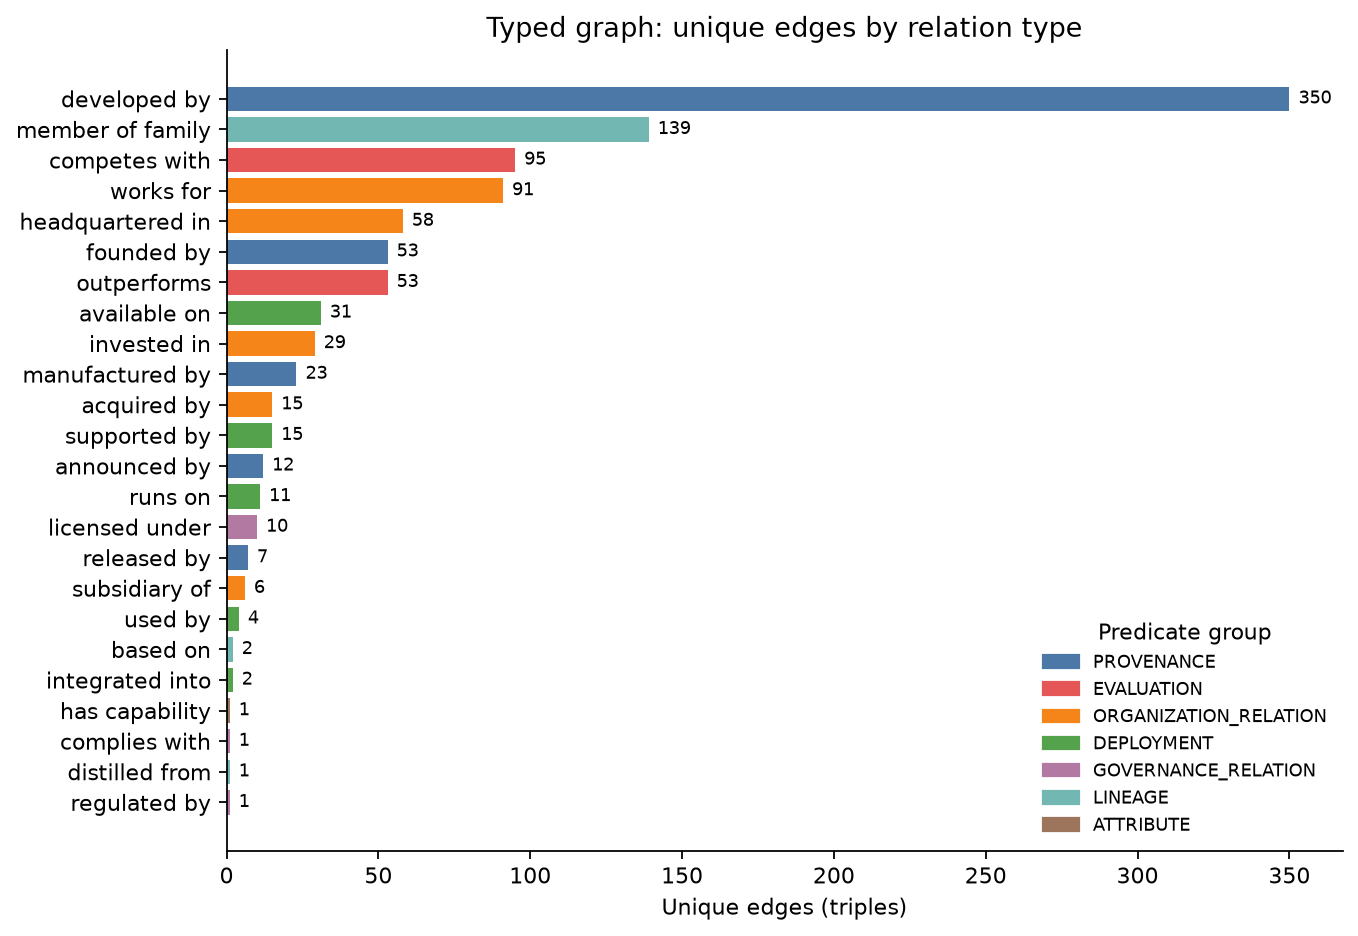

In [14]:
structure = pd.DataFrame({name: graph_summary(graph) for name, graph in
                          [("assertion", assertion_graph), ("typed", typed_graph), ("co-occurrence", cooccurrence_graph)]}).T
ANALYSIS_EXCLUDED_GROUPS = {"ATTRIBUTE"}
analysis_excluded = collapsed["predicate_group"].isin(ANALYSIS_EXCLUDED_GROUPS) | collapsed["added_by"].eq("model_name_member")
collapsed_analysis = collapsed[~analysis_excluded].copy()
excluded_edges = set(zip(collapsed.loc[analysis_excluded, "subject_id"], collapsed.loc[analysis_excluded, "object_id"],
                         collapsed.loc[analysis_excluded, "predicate"]))
typed_analysis_graph = typed_graph.copy()
typed_analysis_graph.remove_edges_from([edge for edge in typed_graph.edges(keys=True) if edge in excluded_edges])
typed_analysis_graph.remove_nodes_from(list(nx.isolates(typed_analysis_graph)))
structure.loc["typed (analysis view)"] = pd.Series(graph_summary(typed_analysis_graph))
typed_undirected = nx.Graph(typed_analysis_graph.to_undirected())
structure.loc["typed (analysis view)", "largest_component_nodes"] = len(max(nx.connected_components(typed_undirected), key=len))
structure.loc["co-occurrence", "largest_component_nodes"] = len(max(nx.connected_components(cooccurrence_graph), key=len))
display(structure)

relation_summary = build_relation_type_summary(collapsed)
relation_summary.insert(1, "predicate_group", relation_summary["predicate"].map(PREDICATE_GROUP))
display(relation_summary)

GROUP_COLORS = {"PROVENANCE": "#4C78A8", "EVALUATION": "#E45756", "ORGANIZATION_RELATION": "#F58518",
                "DEPLOYMENT": "#54A24B", "GOVERNANCE_RELATION": "#B279A2", "LINEAGE": "#72B7B2",
                "ATTRIBUTE": "#9D755D", "TRAINING": "#EECA3B"}
COMPACT_COLORS = {"MODEL": "#4C78A8", "ORGANIZATION": "#F58518", "PERSON": "#9D755D", "INFRASTRUCTURE": "#72B7B2",
                  "TECHNICAL_COMPONENT": "#54A24B", "MODEL_ATTRIBUTE": "#B279A2", "EVALUATION_RESOURCE": "#EECA3B",
                  "GOVERNANCE": "#E45756", "LOCATION_OR_GROUP": "#BAB0AC"}
plot_data = relation_summary.sort_values("unique_edges")
fig, ax = plt.subplots(figsize=(9, 6.5))
ax.barh(plot_data["predicate"], plot_data["unique_edges"], color=plot_data["predicate_group"].map(GROUP_COLORS))
for y, value in enumerate(plot_data["unique_edges"]):
    ax.text(value + 3, y, str(value), va="center", fontsize=8)
ax.legend(handles=[Patch(color=c, label=g) for g, c in GROUP_COLORS.items() if g in set(plot_data["predicate_group"])],
          title="Predicate group", frameon=False, loc="lower right", fontsize=8)
ax.set(title="Typed graph: unique edges by relation type", xlabel="Unique edges (triples)", ylabel="")
save_figure(fig, "01_relation_type_counts.png")

## 10. Centrality

Three measures describe how central an entity is, with the number of supporting articles as edge weight:

- **weighted degree**: total supporting articles of the entity's edges;
- **PageRank**: high when an entity is connected to other central entities;
- **betweenness**: how often an entity lies on shortest paths between others (sample-based approximation).

PageRank and betweenness of the typed graph are computed on the undirected projection of the analysis view.
Direction matters for individual relations, so they are also analysed separately: for `developed by`
(artefact -> organisation) the in-degree of an organisation is the number of its artefacts in the graph.

In [15]:
typed_metrics = calculate_node_metrics(typed_analysis_graph, "typed", "weight", sample_size=1000, seed=SEED)
cooc_metrics = calculate_node_metrics(cooccurrence_graph, "cooccurrence", "document_count", sample_size=500, seed=SEED)
for metrics in (typed_metrics, cooc_metrics):
    metrics["entity_type_compact"] = metrics["entity_id"].map(node_index["entity_type_compact"])

metric_columns = ["canonical_name", "entity_type_compact", "degree", "in_degree", "out_degree",
                  "weighted_degree", "pagerank", "betweenness"]
print("Typed graph: top 15 by PageRank")
display(typed_metrics.head(15)[metric_columns].round(4))
print("Co-occurrence graph: top 15 by PageRank")
display(cooc_metrics.head(15)[[c for c in metric_columns if c in cooc_metrics]].round(4))

relation_metrics = calculate_relation_type_metrics(nodes_kg, collapsed_analysis, sample_size=300, seed=SEED)
relation_views = {"developed by": ("in_degree", "organisations with the most artefacts"),
                  "competes with": ("degree", "entities with the most competitors"),
                  "works for": ("in_degree", "organisations with the most named people"),
                  "outperforms": ("out_degree", "models most often described as better than another")}
for predicate, (column, description) in relation_views.items():
    view = relation_metrics[relation_metrics["predicate"] == predicate]
    print(f"[{predicate}] {description} (by {column})")
    display(view.sort_values([column, "weighted_degree"], ascending=False)
            .head(8)[["canonical_name", "entity_type", column, "weighted_degree"]])

Typed graph: top 15 by PageRank


,canonical_name,entity_type_compact,degree,in_degree,out_degree,weighted_degree,pagerank,betweenness
0,NVIDIA,ORGANIZATION,130,119,11,533.0,0.0607,0.2116
1,OpenAI,ORGANIZATION,76,65,11,754.0,0.0544,0.3200
2,Google,ORGANIZATION,84,70,14,578.0,0.0474,0.2075
3,DeepSeek,ORGANIZATION,65,30,35,568.0,0.0389,0.1336
4,Meta,ORGANIZATION,47,37,10,399.0,0.0290,0.0649
5,Anthropic,ORGANIZATION,42,31,11,324.0,0.0244,0.0480
6,Microsoft,ORGANIZATION,45,32,13,244.0,0.0203,0.0613
7,Llama,MODEL,16,8,8,165.0,0.0109,0.0084
8,Amazon,ORGANIZATION,23,12,11,122.0,0.0100,0.0271
9,Nemotron,MODEL,9,1,8,102.0,0.0099,0.0143


Co-occurrence graph: top 15 by PageRank


,canonical_name,entity_type_compact,degree,weighted_degree,pagerank,betweenness
0,NVIDIA,ORGANIZATION,1097,11408.0,0.0319,0.3033
1,DeepSeek,ORGANIZATION,900,12345.0,0.0311,0.1936
2,OpenAI,ORGANIZATION,726,12815.0,0.0302,0.2908
3,Google,ORGANIZATION,802,10919.0,0.0278,0.2222
4,united_states,LOCATION_OR_GROUP,627,9174.0,0.0219,0.1237
5,open_source_model,MODEL_ATTRIBUTE,541,9129.0,0.0214,0.1004
6,Llama,MODEL,611,8208.0,0.0206,0.0880
7,China,LOCATION_OR_GROUP,498,7044.0,0.0166,0.0269
8,Meta,ORGANIZATION,435,6854.0,0.0157,0.0356
9,Anthropic,ORGANIZATION,417,6936.0,0.0155,0.0266


[developed by] organisations with the most artefacts (by in_degree)


...

,canonical_name,entity_type,degree,weighted_degree
70,OpenAI,COMPANY,16,385.0
71,Google,COMPANY,16,314.0
72,DeepSeek,COMPANY,12,228.0
76,NVIDIA,COMPANY,12,79.0
75,Microsoft,COMPANY,11,131.0
73,Anthropic,COMPANY,10,210.0
74,Meta,COMPANY,10,187.0
79,Alibaba,COMPANY,10,81.0


[works for] organisations with the most named people (by in_degree)


,canonical_name,entity_type,in_degree,weighted_degree
857,NVIDIA,COMPANY,10,26.0
858,Meta,COMPANY,6,29.0
860,Microsoft,COMPANY,6,14.0
859,Google,COMPANY,6,9.0
862,OpenAI,COMPANY,3,12.0
861,Anthropic,COMPANY,3,6.0
863,IBM,COMPANY,3,5.0
864,Red Hat,COMPANY,3,3.0


[outperforms] models most often described as better than another (by out_degree)


,canonical_name,entity_type,out_degree,weighted_degree
752,DeepSeek,COMPANY,9,74.0
754,Qwen,FOUNDATION_MODEL,5,29.0
756,GPT-4o,AI_MODEL,4,19.0
755,Kimi,FOUNDATION_MODEL,4,18.0
757,Mistral,FOUNDATION_MODEL,3,14.0
762,GLM,FOUNDATION_MODEL,3,9.0
766,Phi,FOUNDATION_MODEL,3,9.0
753,Llama,FOUNDATION_MODEL,2,31.0


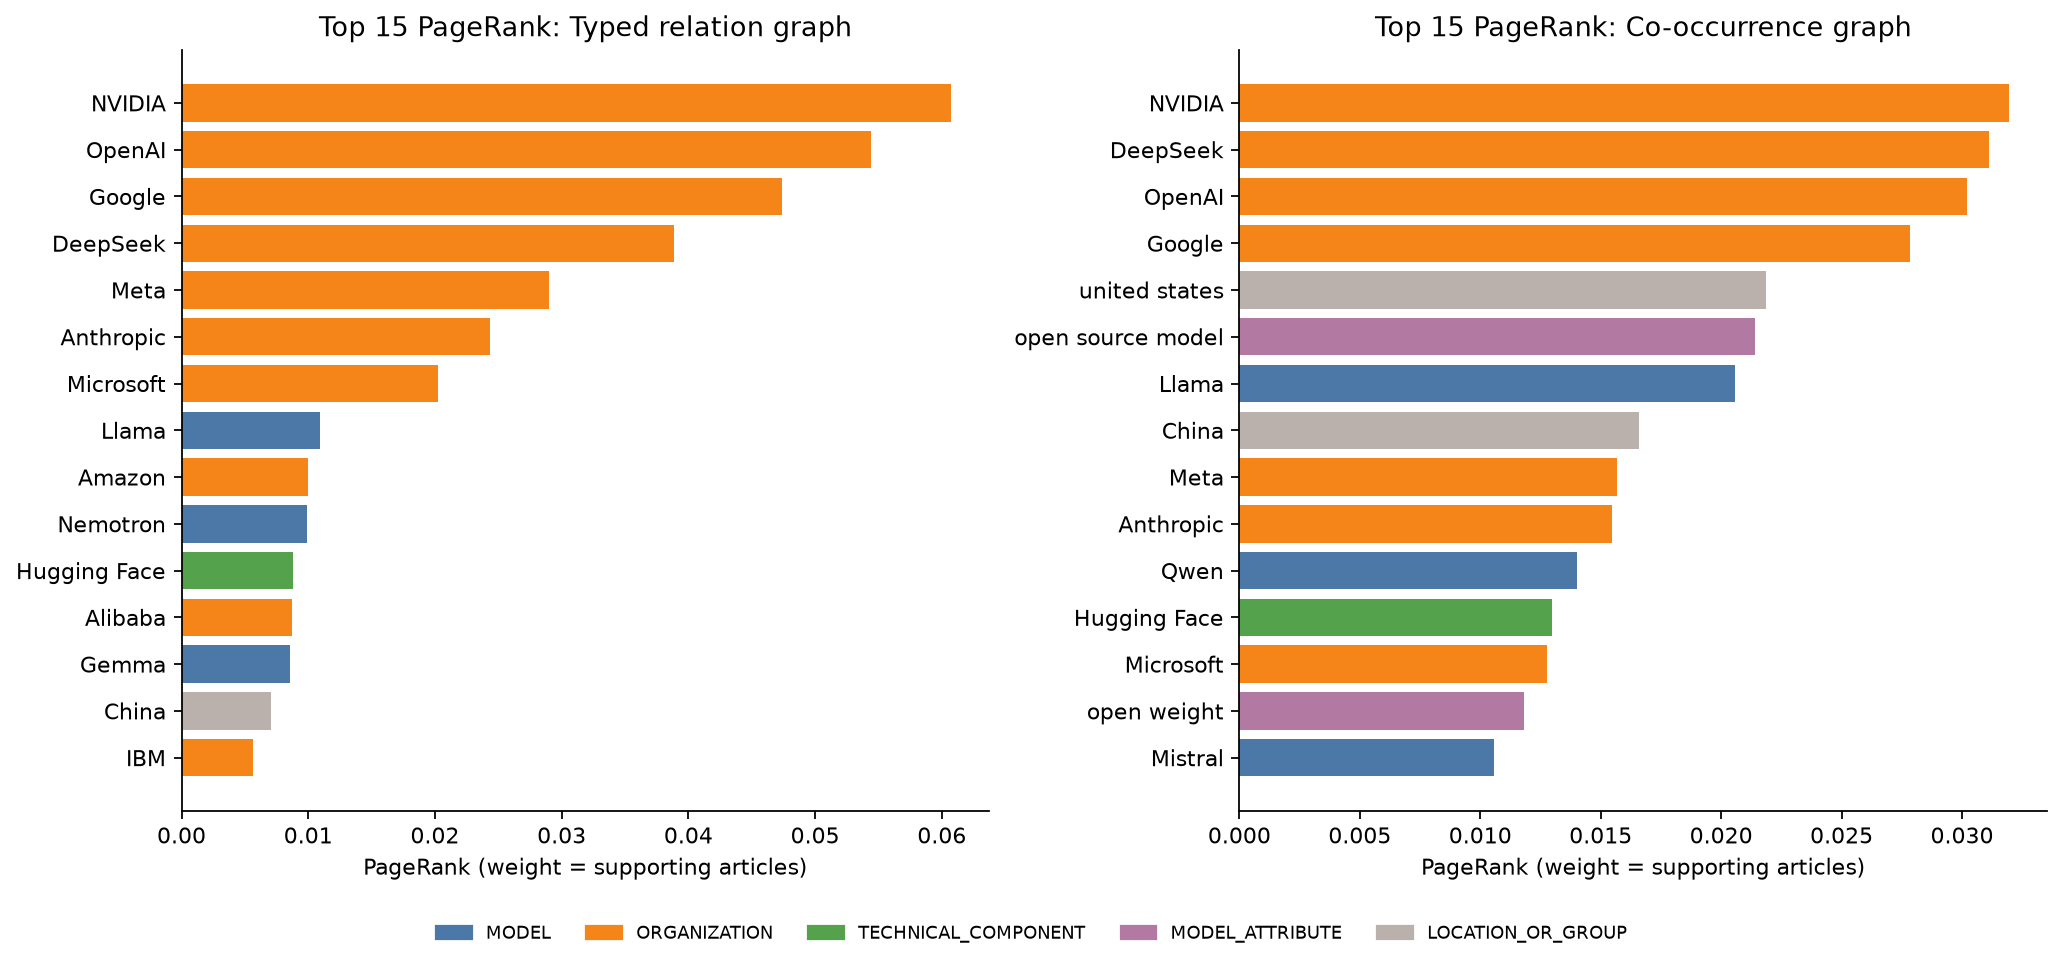


**Interpretation**

- The seven highest-PageRank entities of the typed graph are NVIDIA, OpenAI, Google, DeepSeek, Meta, Anthropic, Microsoft
  (ORGANIZATION). Open model families in the top 15:
  Llama, Nemotron, Gemma.
- **NVIDIA** has the highest `developed by` in-degree (63), but
  41 of these artefacts are infrastructure (GPUs, systems, software) and
  10 are models. Some products also appear under several names (e.g. Blackwell architecture, Blackwell GPU architecture, Grace Blackwell architecture, Blackwell GPUs),
  so the count is larger than the number of products. It reads as "the company with the most named products in the
  articles" rather than "the company that develops the most". Counting models only, **OpenAI**
  has the most (29).
- **OpenAI** has both the highest `competes with` weight (385 supporting articles) and the highest betweenness (0.32) in the typed graph: it connects otherwise separate parts of the graph.
- The co-occurrence ranking also contains context entities (united states, open source model, China, open weight), which reflect the background
  of the reporting (US-China competition, the open vs. closed debate) rather than typed relations.
- 12 of the top-20 entities are shared by both views: the set of central actors is fairly stable, but
  ranks depend on the graph view and thresholds and are not a measure of industry influence.


In [16]:
fig, axes = plt.subplots(1, 2, figsize=(13, 6))
for ax, metrics, title in [(axes[0], typed_metrics, "Typed relation graph"), (axes[1], cooc_metrics, "Co-occurrence graph")]:
    top = metrics.head(15).iloc[::-1]
    ax.barh(top["canonical_name"].map(pretty), top["pagerank"], color=top["entity_type_compact"].map(COMPACT_COLORS))
    ax.set(title=f"Top 15 PageRank: {title}", xlabel="PageRank (weight = supporting articles)")
present = set(typed_metrics.head(15)["entity_type_compact"]) | set(cooc_metrics.head(15)["entity_type_compact"])
fig.legend(handles=[Patch(color=COMPACT_COLORS[t], label=t) for t in COMPACT_COLORS if t in present],
           loc="lower center", ncol=len(present), frameon=False, fontsize=8)
fig.tight_layout(rect=(0, 0.05, 1, 1))
save_figure(fig, "02_pagerank_typed_vs_cooccurrence.png")

labels = node_index["canonical_name"]
top_typed = typed_metrics.head(7)
dev = relation_metrics[relation_metrics["predicate"] == "developed by"].nlargest(1, "in_degree").iloc[0]
developed = collapsed[collapsed["predicate"] == "developed by"].assign(
    product_type=lambda d: d["subject_id"].map(node_index["entity_type_compact"]))
dev_products = developed[developed["object_id"] == dev["entity_id"]]
dev_mix = dev_products["product_type"].value_counts()
model_leader = developed[developed["product_type"] == "MODEL"]["object_id"].value_counts()
fragments = [n for n in dev_products["subject_id"].map(labels) if "Blackwell" in n]
competition = relation_metrics[relation_metrics["predicate"] == "competes with"].nlargest(1, "weighted_degree").iloc[0]
bridge = typed_metrics.nlargest(1, "betweenness").iloc[0]
context = cooc_metrics.head(15)
context = context[context["entity_type_compact"].isin(["LOCATION_OR_GROUP", "MODEL_ATTRIBUTE"])]["canonical_name"].map(pretty)
overlap = set(typed_metrics.head(20)["entity_id"]) & set(cooc_metrics.head(20)["entity_id"])
if competition["entity_id"] == bridge["entity_id"]:
    competition_text = (f"**{competition['canonical_name']}** has both the highest `competes with` weight "
                        f"({int(competition['weighted_degree'])} supporting articles) and the highest betweenness "
                        f"({bridge['betweenness']:.2f}) in the typed graph: it connects otherwise separate parts of the graph.")
else:
    competition_text = (f"**{competition['canonical_name']}** has the highest `competes with` weight "
                        f"({int(competition['weighted_degree'])} supporting articles), and **{bridge['canonical_name']}** "
                        f"has the highest betweenness ({bridge['betweenness']:.2f}) in the typed graph.")
display(Markdown(f'''
**Interpretation**

- The seven highest-PageRank entities of the typed graph are {", ".join(top_typed["canonical_name"])}
  ({", ".join(sorted(set(top_typed["entity_type_compact"])))}). Open model families in the top 15:
  {", ".join(typed_metrics.head(15).query("entity_type_compact == 'MODEL'")["canonical_name"])}.
- **{dev["canonical_name"]}** has the highest `developed by` in-degree ({int(dev["in_degree"])}), but
  {dev_mix.get("INFRASTRUCTURE", 0)} of these artefacts are infrastructure (GPUs, systems, software) and
  {dev_mix.get("MODEL", 0)} are models. Some products also appear under several names (e.g. {", ".join(fragments[:4])}),
  so the count is larger than the number of products. It reads as "the company with the most named products in the
  articles" rather than "the company that develops the most". Counting models only, **{labels[model_leader.index[0]]}**
  has the most ({model_leader.iloc[0]}).
- {competition_text}
- The co-occurrence ranking also contains context entities ({", ".join(context)}), which reflect the background
  of the reporting (US-China competition, the open vs. closed debate) rather than typed relations.
- {len(overlap)} of the top-20 entities are shared by both views: the set of central actors is fairly stable, but
  ranks depend on the graph view and thresholds and are not a measure of industry influence.
'''))

## 11. Clustering and communities

Groups of entities that are mentioned together show the sub-themes of the open-model discourse. Clustering is
meaningful on the triangle-rich co-occurrence graph and naturally low on the star-shaped typed graph. Communities
are detected with greedy modularity, using the number of shared articles as weight.

In [17]:
clustering_table = pd.DataFrame(
    [("typed (undirected projection)", nx.average_clustering(typed_undirected), np.nan, nx.transitivity(typed_undirected)),
     ("co-occurrence", nx.average_clustering(cooccurrence_graph),
      nx.average_clustering(cooccurrence_graph, weight="document_count"), nx.transitivity(cooccurrence_graph))],
    columns=["view", "average clustering", "weighted average clustering", "transitivity"],
).round(4)
display(clustering_table)

community_members, community_summary = detect_cooccurrence_communities(cooccurrence_graph)
community_sets = [set(group["entity_id"]) for _, group in community_members.groupby("community_id")]
modularity = nx.community.modularity(cooccurrence_graph, community_sets, weight="document_count")
community_summary["top_entities"] = community_summary["top_entities"].map(lambda v: ", ".join(json.loads(v)[:8]))
community_summary["share_of_nodes"] = (community_summary["node_count"] / cooccurrence_graph.number_of_nodes()).round(3)
print(f"{len(community_summary)} communities, modularity {modularity:.3f}")
display(community_summary.head(10))

,view,average clustering,weighted average clustering,transitivity
0,typed (undirected projection),0.0647,NaN,0.0491
1,co-occurrence,0.5405,0.008,0.0784


193 communities, modularity 0.237


,community_id,node_count,edge_count,top_entities,share_of_nodes
0,1,1665,6759,"OpenAI, Google, open_source_model, Llama, Anth...",0.343
1,2,1327,3854,"united_states, DeepSeek, China, NVIDIA, Micros...",0.273
2,3,894,3584,"vllm, Nemotron, Google Cloud, IBM, Dell Techno...",0.184
3,4,124,313,"TrueFoundry, observability, routing, reliabili...",0.026
4,5,97,162,"MLA, Grouped-Query Attention, Multi-Head Atten...",0.020
5,6,44,65,"Facebook, Instagram, WhatsApp, Discord, Messen...",0.009
6,7,29,36,"MLLM, ControlNet, CLIP, T5-XXL, SD3, IP-Adapte...",0.006
7,8,16,32,"Kit, WebGPU, personality, Nico, Michael Knight...",0.003
8,9,16,25,"Liquid AI, LFMs, liquid neural networks, Fruga...",0.003
9,10,16,49,"Arka Venture Labs, Astir VC, Good News Venture...",0.003


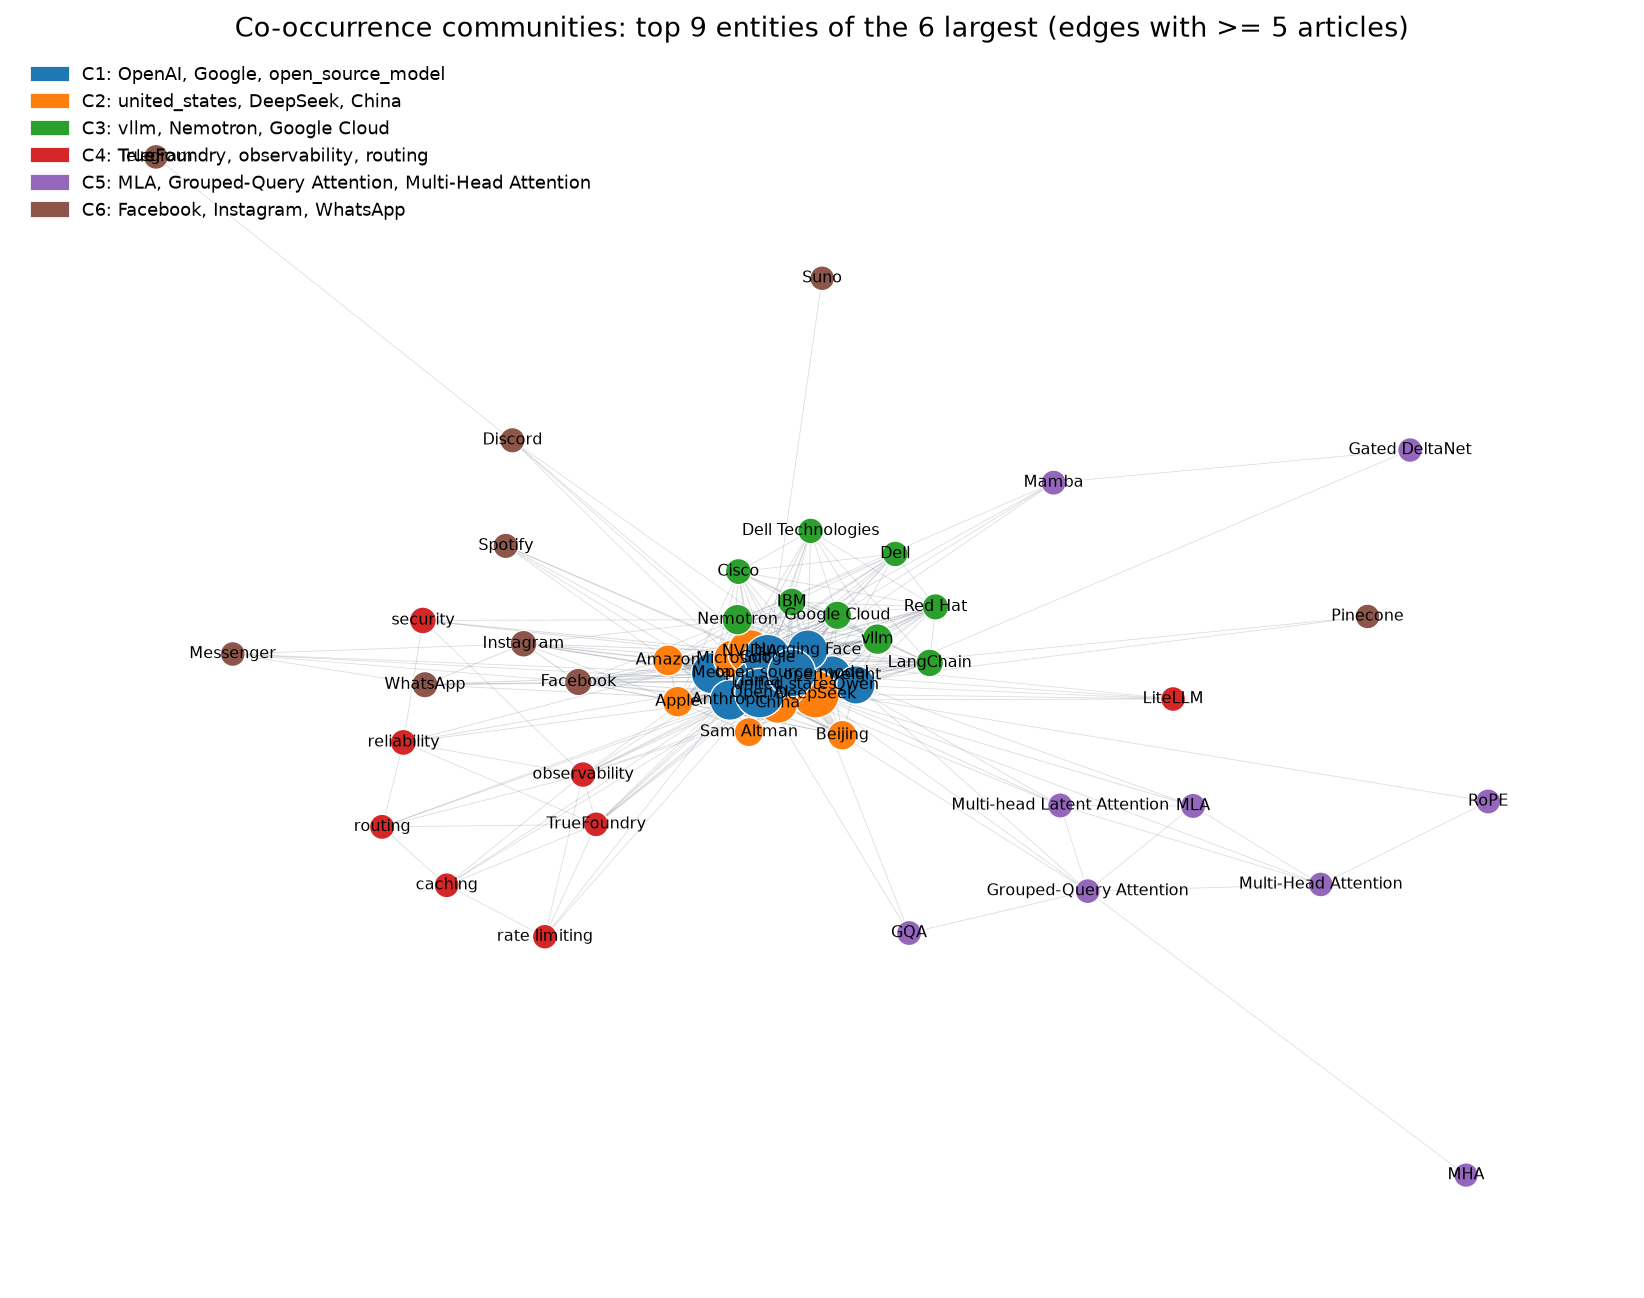


**Interpretation**

- Average clustering is 0.54 in the co-occurrence graph and
  0.06 in the typed graph: co-mentions in one article form triangles,
  typed relations mostly form stars (many models -> one developer).
- Modularity is low (0.24) because the main organisations and models are mentioned across most
  articles. The three largest communities still cover 80% of the nodes
  and read as distinct themes:
  - **C1 (34%)** OpenAI, Google, open source model, Llama, Anthropic, Qwen, Meta, open weight: major model developers and the open vs. closed model discourse;
  - **C2 (27%)** united states, DeepSeek, China, NVIDIA, Microsoft, Beijing, Apple, Sam Altman: US-China AI competition and compute infrastructure;
  - **C3 (18%)** vllm, Nemotron, Google Cloud, IBM, Dell Technologies, Cisco, Red Hat, LangChain: enterprise deployment, inference and cloud ecosystem.
- Smaller communities are single topics, e.g. TrueFoundry (124 nodes)
  and MLA (97 nodes).
- Community names are interpretations of their top entities.


In [18]:
TOP_COMMUNITIES, NODES_PER_COMMUNITY = 6, 9
top_members = community_members[(community_members["community_id"] <= TOP_COMMUNITIES)
                                & (community_members["rank_in_community"] <= NODES_PER_COMMUNITY)]
draw = cooccurrence_graph.subgraph(top_members["entity_id"]).copy()
draw.remove_edges_from([(a, b) for a, b, d in draw.edges(data=True) if d["document_count"] < DRAW_COOCCURRENCE_DOCUMENTS])
draw.remove_nodes_from(list(nx.isolates(draw)))
community_of = top_members.set_index("entity_id")["community_id"]
palette = plt.get_cmap("tab10")
positions = nx.spring_layout(draw, seed=SEED, weight="document_count", k=2.4 / np.sqrt(max(len(draw), 1)), iterations=500)
fig, ax = plt.subplots(figsize=(13, 10))
max_docs = max(nx.get_edge_attributes(draw, "document_count").values())
nx.draw_networkx_edges(draw, positions, width=[0.3 + 2.5 * d["document_count"] / max_docs for _, _, d in draw.edges(data=True)],
                       alpha=0.25, edge_color="#6B7280", ax=ax)
nx.draw_networkx_nodes(draw, positions, ax=ax, linewidths=0.6, edgecolors="white",
                       node_color=[palette(community_of[n] - 1) for n in draw],
                       node_size=[120 + 0.6 * draw.nodes[n]["document_count"] for n in draw])
nx.draw_networkx_labels(draw, positions, labels={n: pretty(draw.nodes[n]["label"]) for n in draw}, font_size=7, ax=ax)
legend_labels = community_summary.set_index("community_id")["top_entities"]
ax.legend(handles=[Patch(color=palette(c - 1), label=f"C{c}: " + ", ".join(legend_labels[c].split(", ")[:3]))
                   for c in range(1, TOP_COMMUNITIES + 1)], loc="upper left", frameon=False, fontsize=8)
ax.set_title(f"Co-occurrence communities: top {NODES_PER_COMMUNITY} entities of the {TOP_COMMUNITIES} largest "
             f"(edges with >= {DRAW_COOCCURRENCE_DOCUMENTS} articles)")
ax.axis("off")
save_figure(fig, "03_cooccurrence_communities.png")

c = community_summary.set_index("community_id").assign(top_entities=lambda d: d["top_entities"].map(pretty))
display(Markdown(f'''
**Interpretation**

- Average clustering is {clustering_table.loc[1, "average clustering"]:.2f} in the co-occurrence graph and
  {clustering_table.loc[0, "average clustering"]:.2f} in the typed graph: co-mentions in one article form triangles,
  typed relations mostly form stars (many models -> one developer).
- Modularity is low ({modularity:.2f}) because the main organisations and models are mentioned across most
  articles. The three largest communities still cover {c.loc[[1, 2, 3], "share_of_nodes"].sum():.0%} of the nodes
  and read as distinct themes:
  - **C1 ({c.loc[1, "share_of_nodes"]:.0%})** {c.loc[1, "top_entities"]}: major model developers and the open vs. closed model discourse;
  - **C2 ({c.loc[2, "share_of_nodes"]:.0%})** {c.loc[2, "top_entities"]}: US-China AI competition and compute infrastructure;
  - **C3 ({c.loc[3, "share_of_nodes"]:.0%})** {c.loc[3, "top_entities"]}: enterprise deployment, inference and cloud ecosystem.
- Smaller communities are single topics, e.g. {c.loc[4, "top_entities"].split(", ")[0]} ({c.loc[4, "node_count"]} nodes)
  and {c.loc[5, "top_entities"].split(", ")[0]} ({c.loc[5, "node_count"]} nodes).
- Community names are interpretations of their top entities.
'''))

## 12. Temporal analysis

All dates are article publication dates, so the results describe when relations were *reported* in the corpus.

1. relation evidence sentences per quarter, by predicate group;
2. typed relations first observed per quarter;
3. share of Open Models articles mentioning each top model family per quarter (WP2 `entity_mentions`, one count
   per article);
4. entities whose share of relation evidence changed most between the first and second year;
5. relations first observed in 2026 (emerging relationships). Examples are taken only from relations whose
   evidence sentences were checked by a person.

The first quarter (2024Q3) only contains September and the last (2026Q3) only July and August.

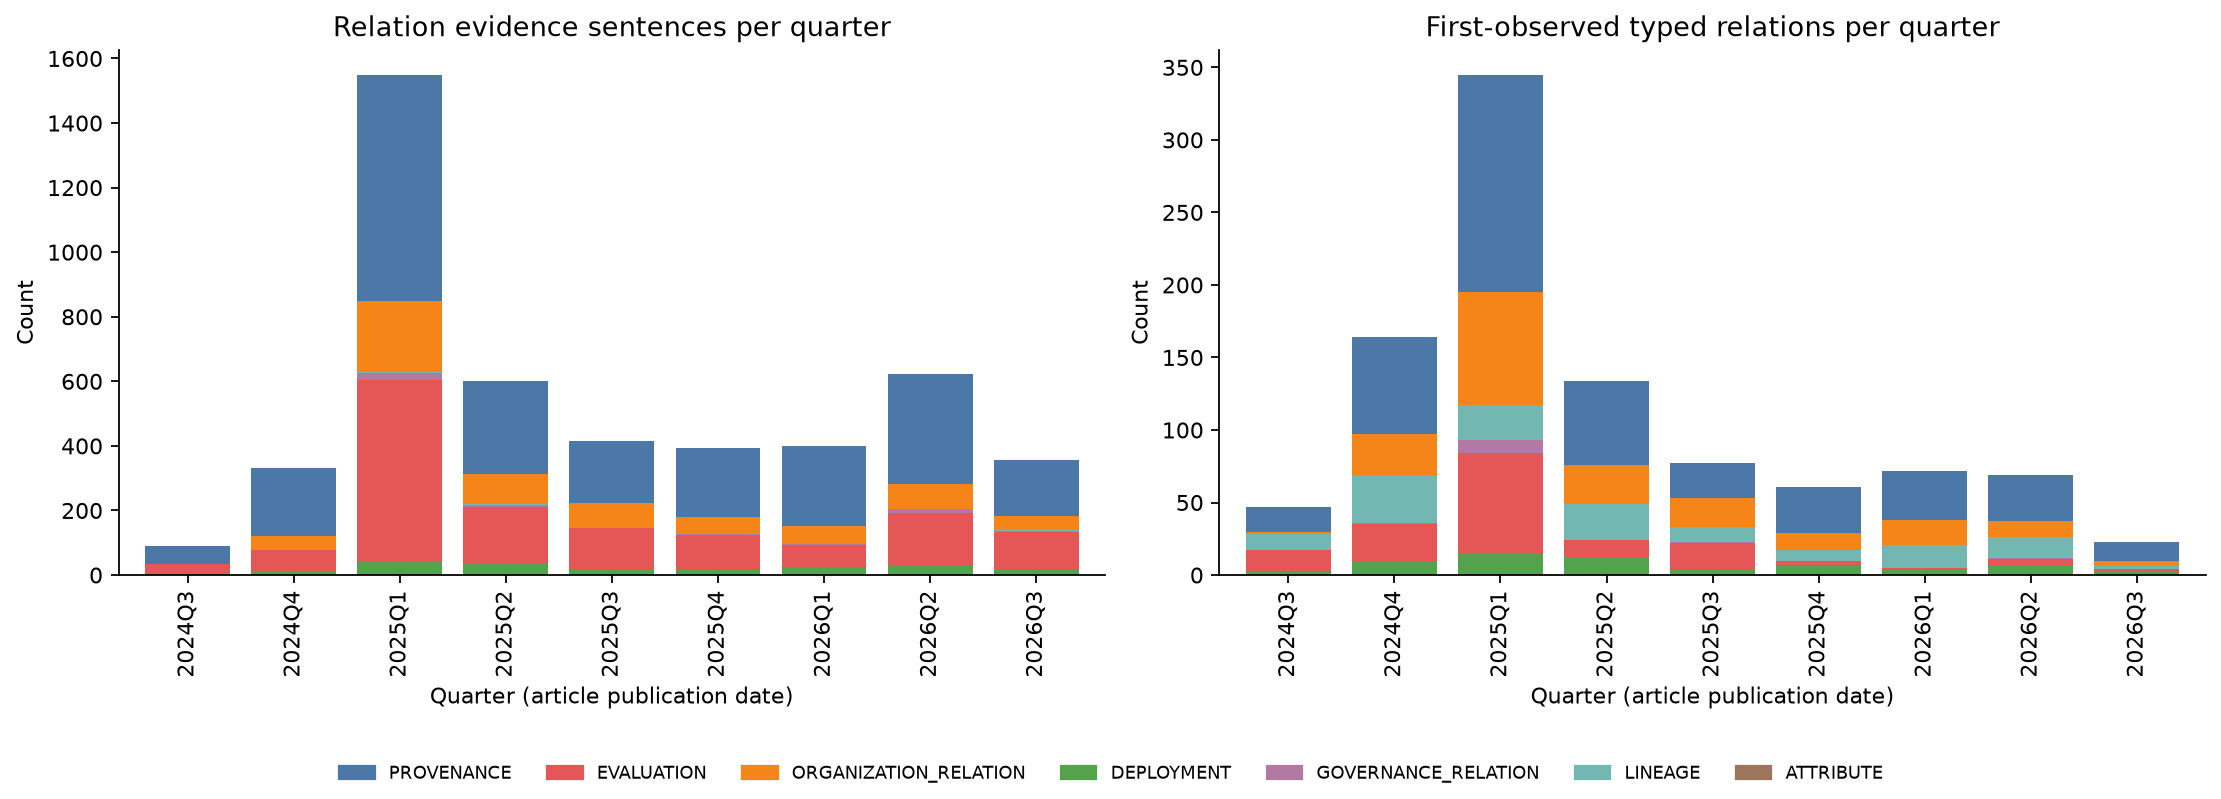

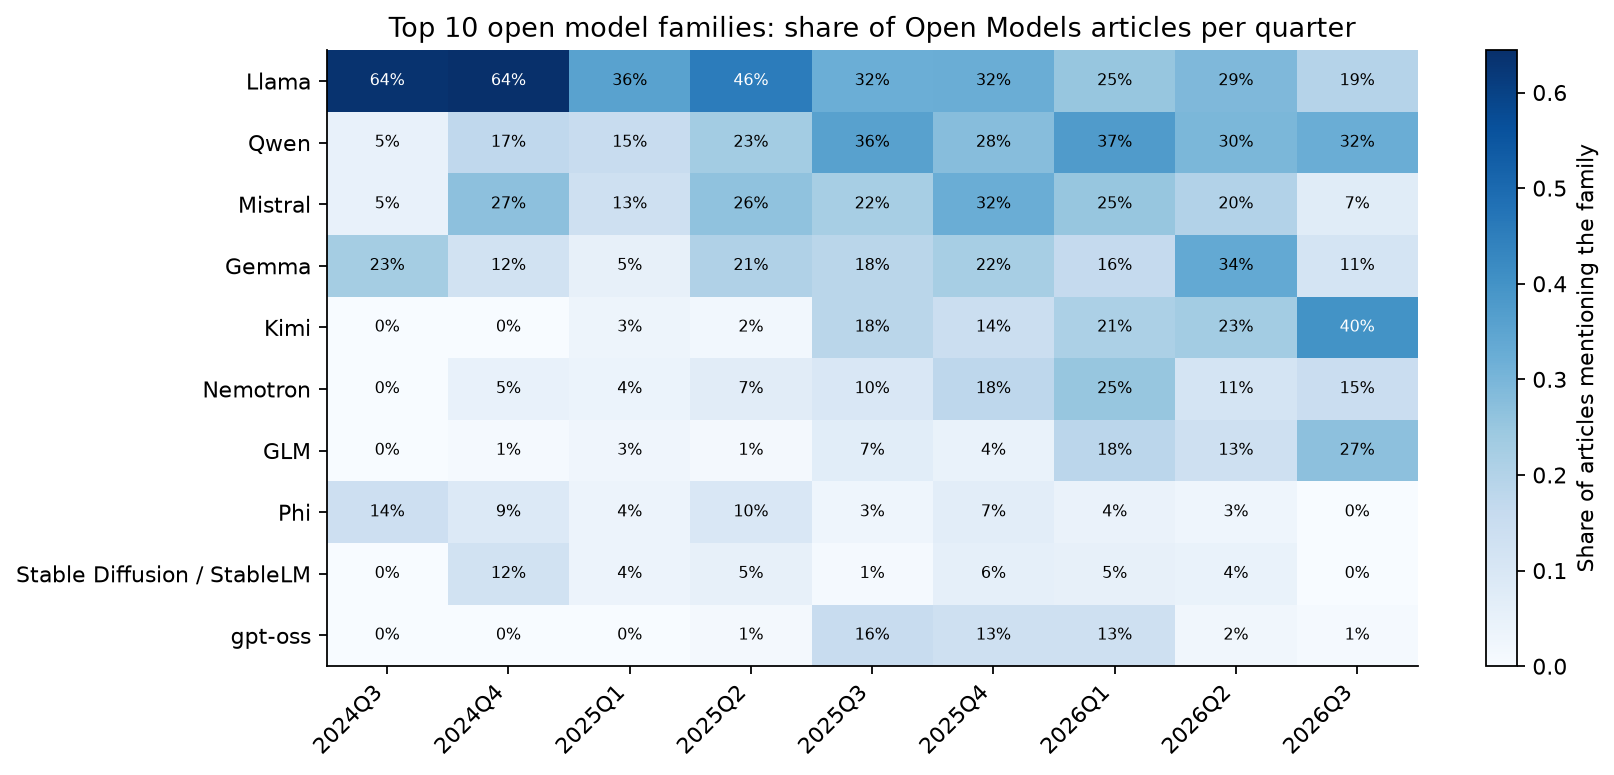

quarter,2024Q3,2024Q4,2025Q1,2025Q2,2025Q3,2025Q4,2026Q1,2026Q2,2026Q3
articles,22,104,349,156,103,90,99,179,108


In [19]:
dated = assertions[assertions["extraction_method"] == "glirel"].copy()
dated["quarter"] = pd.to_datetime(dated["published_at"]).dt.to_period("Q").astype(str)
dated["predicate_group"] = dated["predicate"].map(PREDICATE_GROUP)
quarterly_assertions = dated.pivot_table(index="quarter", columns="predicate_group", values="relation_id",
                                         aggfunc="count", fill_value=0)
new_edges = collapsed[collapsed["first_seen"].notna()].copy()
new_edges["quarter"] = pd.to_datetime(new_edges["first_seen"]).dt.to_period("Q").astype(str)
quarterly_new_edges = new_edges.pivot_table(index="quarter", columns="predicate_group", values="predicate",
                                            aggfunc="count", fill_value=0)

mentions = pd.read_csv(WP2_INPUT_DIR / "entity_mentions.csv", usecols=["entity_id", "doc_id", "quarter"])
articles_per_quarter = mentions.drop_duplicates("doc_id")["quarter"].value_counts().sort_index()
families = nodes_kg[nodes_kg["is_open_model_family"]].set_index("entity_id")["canonical_name"]
family_mentions = mentions.assign(entity_id=mentions["entity_id"].map(id_map))
family_quarterly = (family_mentions[family_mentions["entity_id"].isin(families.index)]
                    .drop_duplicates(["entity_id", "doc_id"])  # an article counts once, even with several merged names
                    .groupby(["entity_id", "quarter"]).size().unstack(fill_value=0))
family_share = family_quarterly.div(articles_per_quarter.reindex(family_quarterly.columns), axis=1)
family_share = family_share.loc[family_quarterly.sum(axis=1).nlargest(10).index].rename(index=families)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, table, title in [(axes[0], quarterly_assertions, "Relation evidence sentences per quarter"),
                         (axes[1], quarterly_new_edges, "First-observed typed relations per quarter")]:
    table.plot(ax=ax, kind="bar", stacked=True, width=0.8, legend=False,
               color=[GROUP_COLORS.get(c, "#BAB0AC") for c in table.columns])
    ax.set(title=title, xlabel="Quarter (article publication date)", ylabel="Count")
handles = [Patch(color=GROUP_COLORS[g], label=g) for g in GROUP_COLORS if g in set(quarterly_assertions.columns)]
fig.legend(handles=handles, loc="lower center", ncol=len(handles), frameon=False, fontsize=8)
fig.tight_layout(rect=(0, 0.07, 1, 1))
save_figure(fig, "04_quarterly_relations.png")

fig, ax = plt.subplots(figsize=(11, 5))
image = ax.imshow(family_share.values, aspect="auto", cmap="Blues")
ax.set_xticks(range(family_share.shape[1]), family_share.columns, rotation=45, ha="right")
ax.set_yticks(range(family_share.shape[0]), family_share.index)
for (i, j), value in np.ndenumerate(family_share.values):
    ax.text(j, i, f"{value:.0%}", ha="center", va="center", fontsize=7,
            color="white" if value > family_share.values.max() * 0.6 else "black")
fig.colorbar(image, ax=ax, label="Share of articles mentioning the family")
ax.set_title("Top 10 open model families: share of Open Models articles per quarter")
save_figure(fig, "05_family_quarterly_share.png")
display(articles_per_quarter.rename("articles").to_frame().T)

In [20]:
dated_analysis = dated[~dated["predicate_group"].isin(ANALYSIS_EXCLUDED_GROUPS)]

def period_share(start, end):
    rows = dated_analysis[(dated_analysis["published_at"] >= start) & (dated_analysis["published_at"] <= end)]
    long = pd.concat([rows[["subject_id", "document_id"]].rename(columns={"subject_id": "entity_id"}),
                      rows[["object_id", "document_id"]].rename(columns={"object_id": "entity_id"})])
    return long.drop_duplicates().groupby("entity_id")["document_id"].nunique() / rows["document_id"].nunique()

shares = pd.DataFrame({name: period_share(*span) for name, span in PERIODS.items()}).fillna(0)
p1, p2 = shares.columns
shares["change_pp"] = (shares[p2] - shares[p1]) * 100
shares["canonical_name"] = shares.index.map(labels)
shares["entity_type_compact"] = shares.index.map(node_index["entity_type_compact"])
print("Share of relation-evidence articles per entity: change from P1 to P2 (percentage points)")
display(pd.concat([shares.nlargest(10, "change_pp"), shares.nsmallest(5, "change_pp")])
        [["canonical_name", "entity_type_compact", p1, p2, "change_pp"]].round(3))

# Relations first observed in 2026: counts over all of them, examples only from relations checked by a person
VERIFIED_STATUS = ["reviewed_true", "checked_true_human"]
first_seen_2026 = collapsed_analysis[(collapsed_analysis["first_seen"].fillna("") >= "2026-01-01")
                                     & (collapsed_analysis["document_count"] >= 2)].copy()
first_seen_2026["edge"] = (first_seen_2026["subject_id"].map(labels) + " -> " + first_seen_2026["predicate"]
                           + " -> " + first_seen_2026["object_id"].map(labels))
verified_2026 = first_seen_2026[first_seen_2026["review_status"].isin(VERIFIED_STATUS)]
print(f"Relations first observed in 2026 with >= 2 articles: {len(first_seen_2026)} "
      f"({len(verified_2026)} with evidence checked by a person)")
display(verified_2026.nlargest(10, "document_count")[["edge", "predicate_group", "document_count", "first_seen", "review_status"]])

Share of relation-evidence articles per entity: change from P1 to P2 (percentage points)


,canonical_name,entity_type_compact,P1 (2024-09 to 2025-08),P2 (2025-09 to 2026-08),change_pp
entity_id,,,,,
org:anthropic,Anthropic,ORGANIZATION,0.141,0.290,14.841
model:nemotron,Nemotron,MODEL,0.044,0.145,10.081
org:nvidia,NVIDIA,ORGANIZATION,0.193,0.273,8.032
model:kimi,Kimi,MODEL,0.018,0.081,6.243
model:gemma,Gemma,MODEL,0.070,0.128,5.841
org:moonshot_ai,MoonShot AI,ORGANIZATION,0.015,0.056,4.103
org:google,Google,ORGANIZATION,0.306,0.345,3.898
person:jensen_huang,Jensen Huang,PERSON,0.022,0.050,2.812
model:glm,GLM,MODEL,0.006,0.033,2.792


Relations first observed in 2026 with >= 2 articles: 81 (4 with evidence checked by a person)


,edge,predicate_group,document_count,first_seen,review_status
447,NemoClaw -> developed by -> NVIDIA,PROVENANCE,9,2026-03-11,checked_true_human
286,Muse Spark -> developed by -> Meta,PROVENANCE,7,2026-04-08,checked_true_human
254,GPT-5.5 -> developed by -> OpenAI,PROVENANCE,4,2026-04-24,checked_true_human
19,GTC 2026 -> announced by -> NVIDIA,PROVENANCE,2,2026-03-18,checked_true_human


In [21]:
peak_quarter = articles_per_quarter.idxmax()
fs = family_share
first_q = next(q for q in fs.columns if articles_per_quarter[q] >= 50)  # the first quarter has too few articles
last_q = fs.columns[-1]
quarter_totals = quarterly_assertions.sum(axis=1)
risers, fallers = shares.nlargest(5, "change_pp"), shares.nsmallest(3, "change_pp")
display(Markdown(f'''
**Interpretation**

- **{peak_quarter} dominates**: it has the most articles ({articles_per_quarter[peak_quarter]}) and
  {quarter_totals[peak_quarter]:,} relation evidence sentences (median quarter: {int(quarter_totals.median()):,}), the
  period after the DeepSeek-R1 release. Comparisons over time therefore use shares rather than counts.
- **Model families** ({fs.columns[0]} has only {articles_per_quarter[fs.columns[0]]} articles, so {first_q} is the
  baseline): the share of articles mentioning Llama moved from {fs.loc["Llama", first_q]:.0%} ({first_q}) to
  {fs.loc["Llama", last_q]:.0%} ({last_q}), while Qwen moved from {fs.loc["Qwen", first_q]:.0%} to {fs.loc["Qwen", last_q]:.0%},
  Kimi from {fs.loc["Kimi", first_q]:.0%} to {fs.loc["Kimi", last_q]:.0%} and GLM from {fs.loc["GLM", first_q]:.0%} to
  {fs.loc["GLM", last_q]:.0%}. Nemotron peaked at {fs.loc["Nemotron"].max():.0%} in {fs.loc["Nemotron"].idxmax()}.
- **Relation evidence, P1 -> P2**: largest increases for
  {", ".join(f"{r.canonical_name} ({r.change_pp:+.1f} pp)" for r in risers.itertuples())};
  largest decreases for {", ".join(f"{r.canonical_name} ({r.change_pp:+.1f} pp)" for r in fallers.itertuples())}.
- **Relations first observed in 2026**: {len(first_seen_2026)} relations with at least 2 supporting articles, mostly
  {", ".join(f"{g} ({n})" for g, n in first_seen_2026["predicate_group"].value_counts().head(3).items())}. Examples
  whose evidence was checked by a person: {"; ".join(f"{r.edge} ({r.first_seen})" for r in verified_2026.nlargest(3, "document_count").itertuples())}.
  "First observed" is the first publication date in this corpus, not the date the relation began.
'''))


**Interpretation**

- **2025Q1 dominates**: it has the most articles (349) and
  1,550 relation evidence sentences (median quarter: 399), the
  period after the DeepSeek-R1 release. Comparisons over time therefore use shares rather than counts.
- **Model families** (2024Q3 has only 22 articles, so 2024Q4 is the
  baseline): the share of articles mentioning Llama moved from 64% (2024Q4) to
  19% (2026Q3), while Qwen moved from 17% to 32%,
  Kimi from 0% to 40% and GLM from 1% to
  27%. Nemotron peaked at 25% in 2026Q1.
- **Relation evidence, P1 -> P2**: largest increases for
  Anthropic (+14.8 pp), Nemotron (+10.1 pp), NVIDIA (+8.0 pp), Kimi (+6.2 pp), Gemma (+5.8 pp);
  largest decreases for DeepSeek (-28.0 pp), Meta (-13.5 pp), Llama (-10.4 pp).
- **Relations first observed in 2026**: 81 relations with at least 2 supporting articles, mostly
  PROVENANCE (49), ORGANIZATION_RELATION (18), DEPLOYMENT (10). Examples
  whose evidence was checked by a person: NemoClaw -> developed by -> NVIDIA (2026-03-11); Muse Spark -> developed by -> Meta (2026-04-08); GPT-5.5 -> developed by -> OpenAI (2026-04-24).
  "First observed" is the first publication date in this corpus, not the date the relation began.


## 13. Graph visualisations

The full graph is too dense for one figure, so each figure answers one question. Node colour is the compact entity
type and edge colour the predicate group; thresholds are stated in the titles.

1. **Core typed graph**: relations among the entities with the highest PageRank (solid: article evidence,
   dashed: WP1 lexicon only).
2. **Open model families -> developer**: article support of each family-developer pair. `developed by` and
   `released by` are combined, and research units are shown with their parent company (Google DeepMind with Google).
3. **Competition and benchmark claims**: `competes with` (no direction) and `outperforms` (arrow).

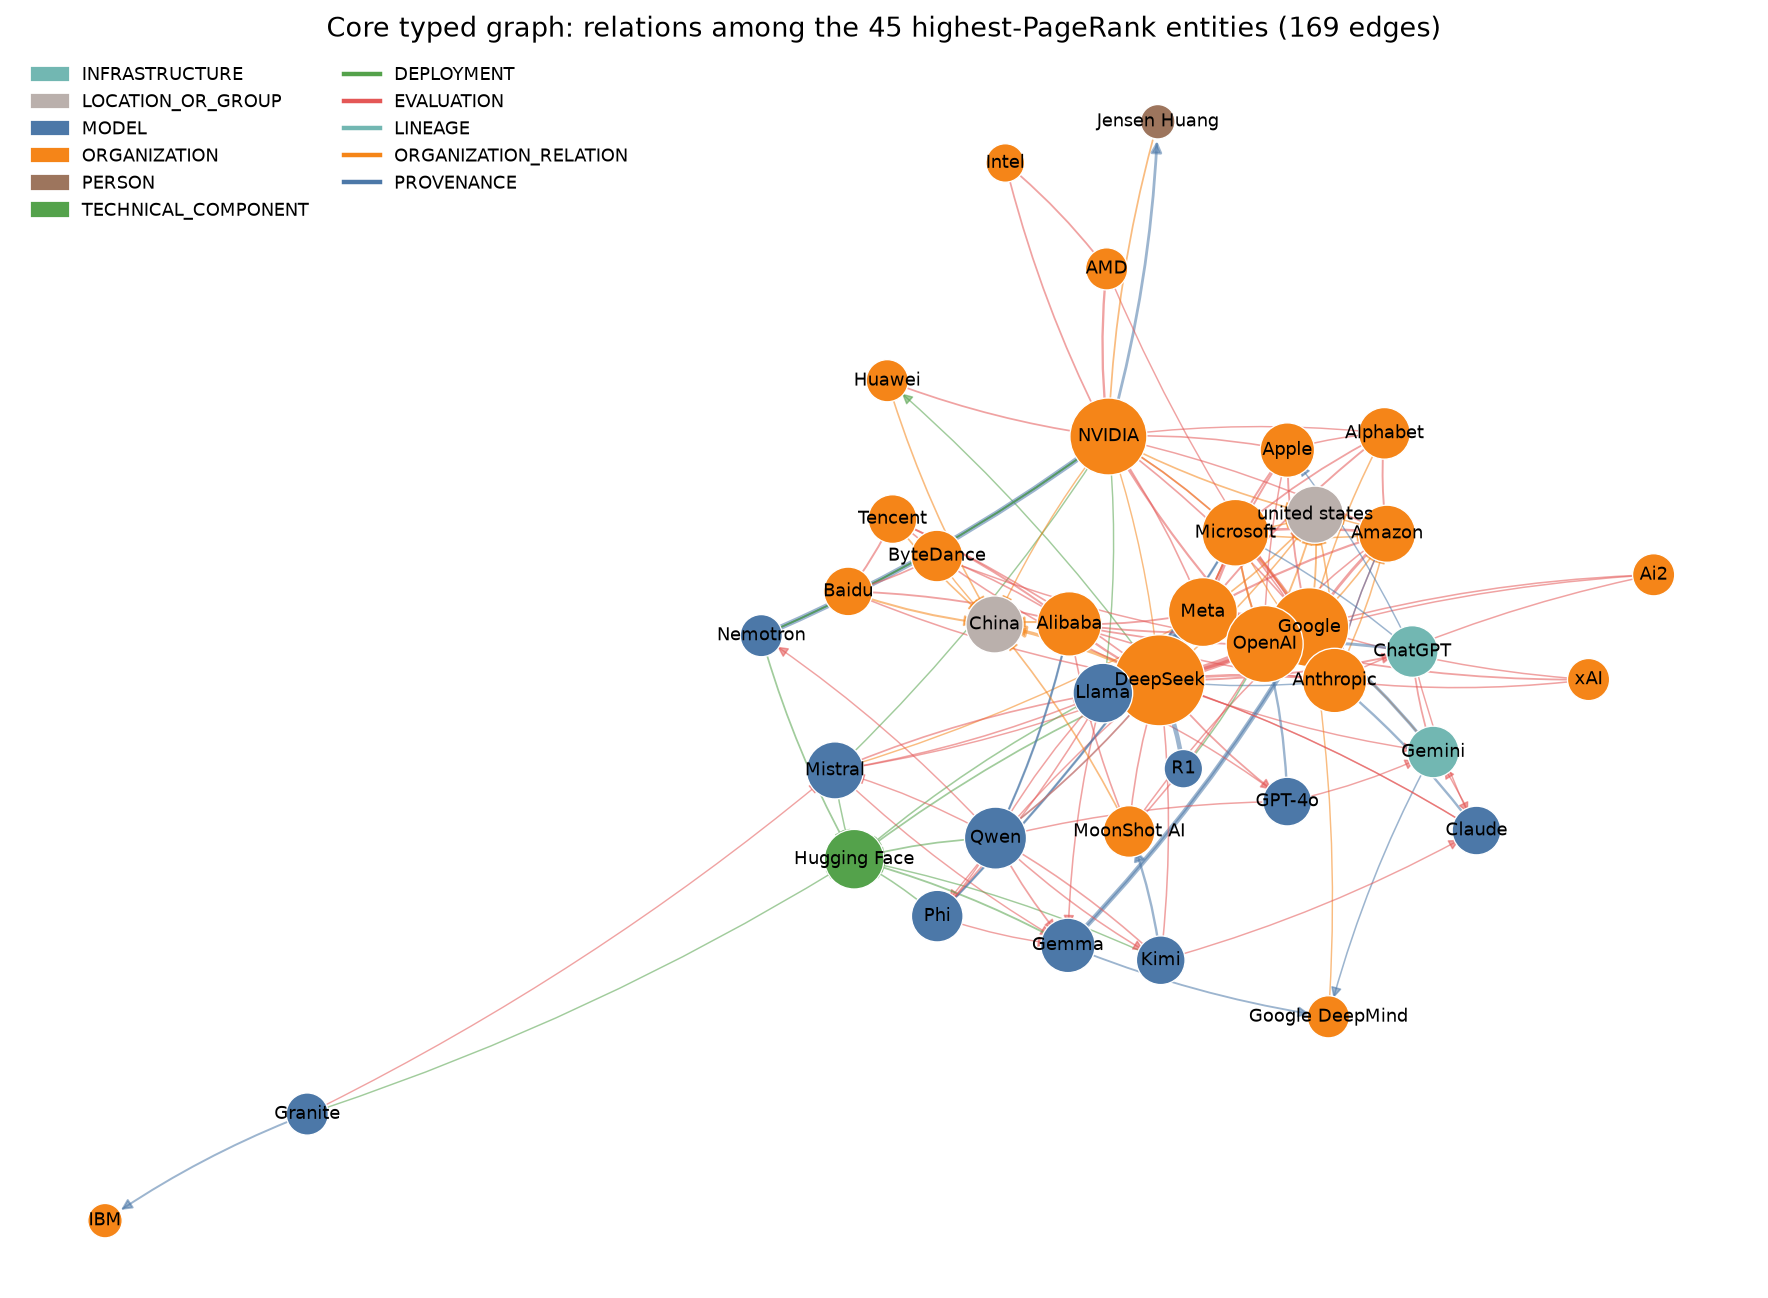

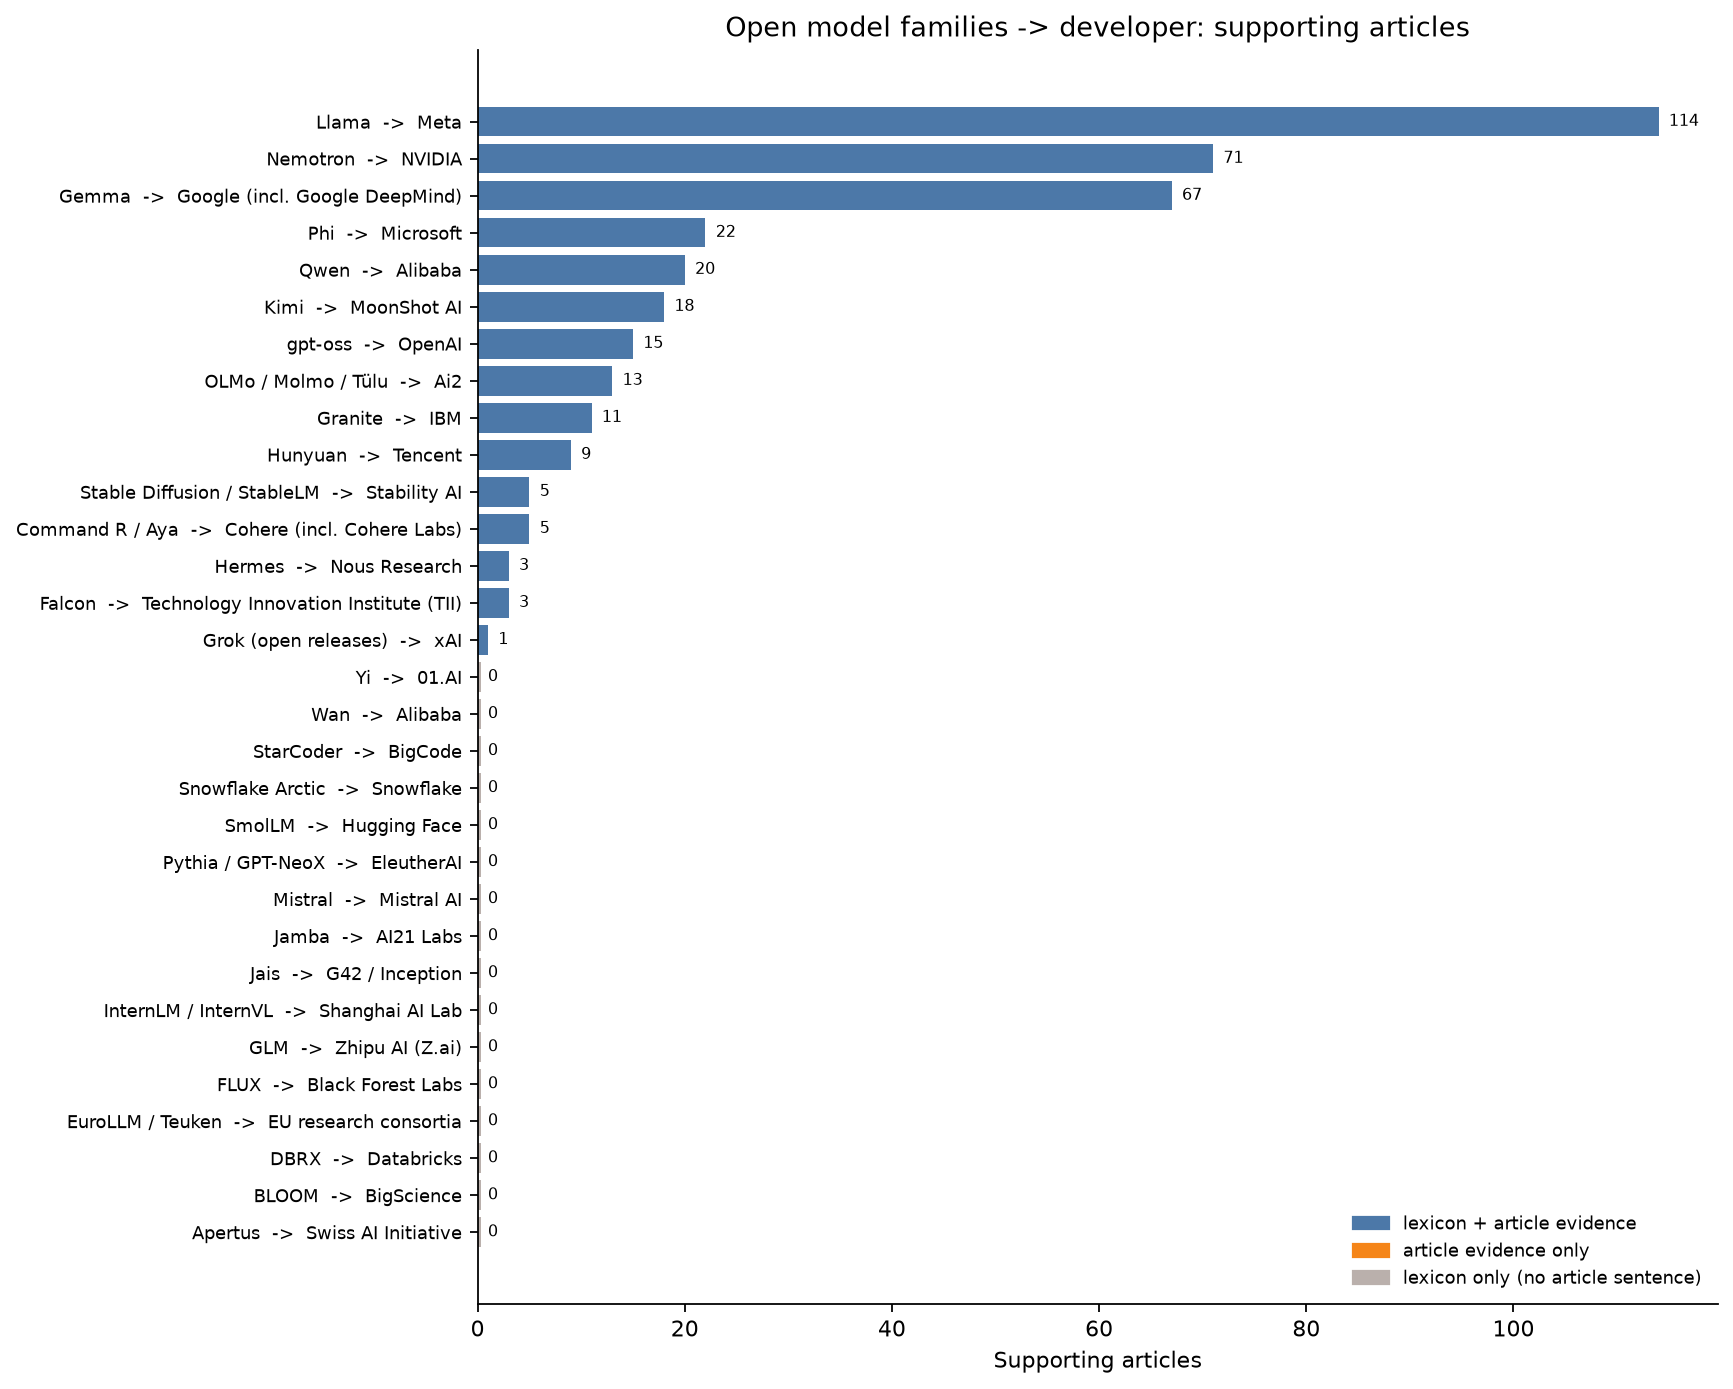

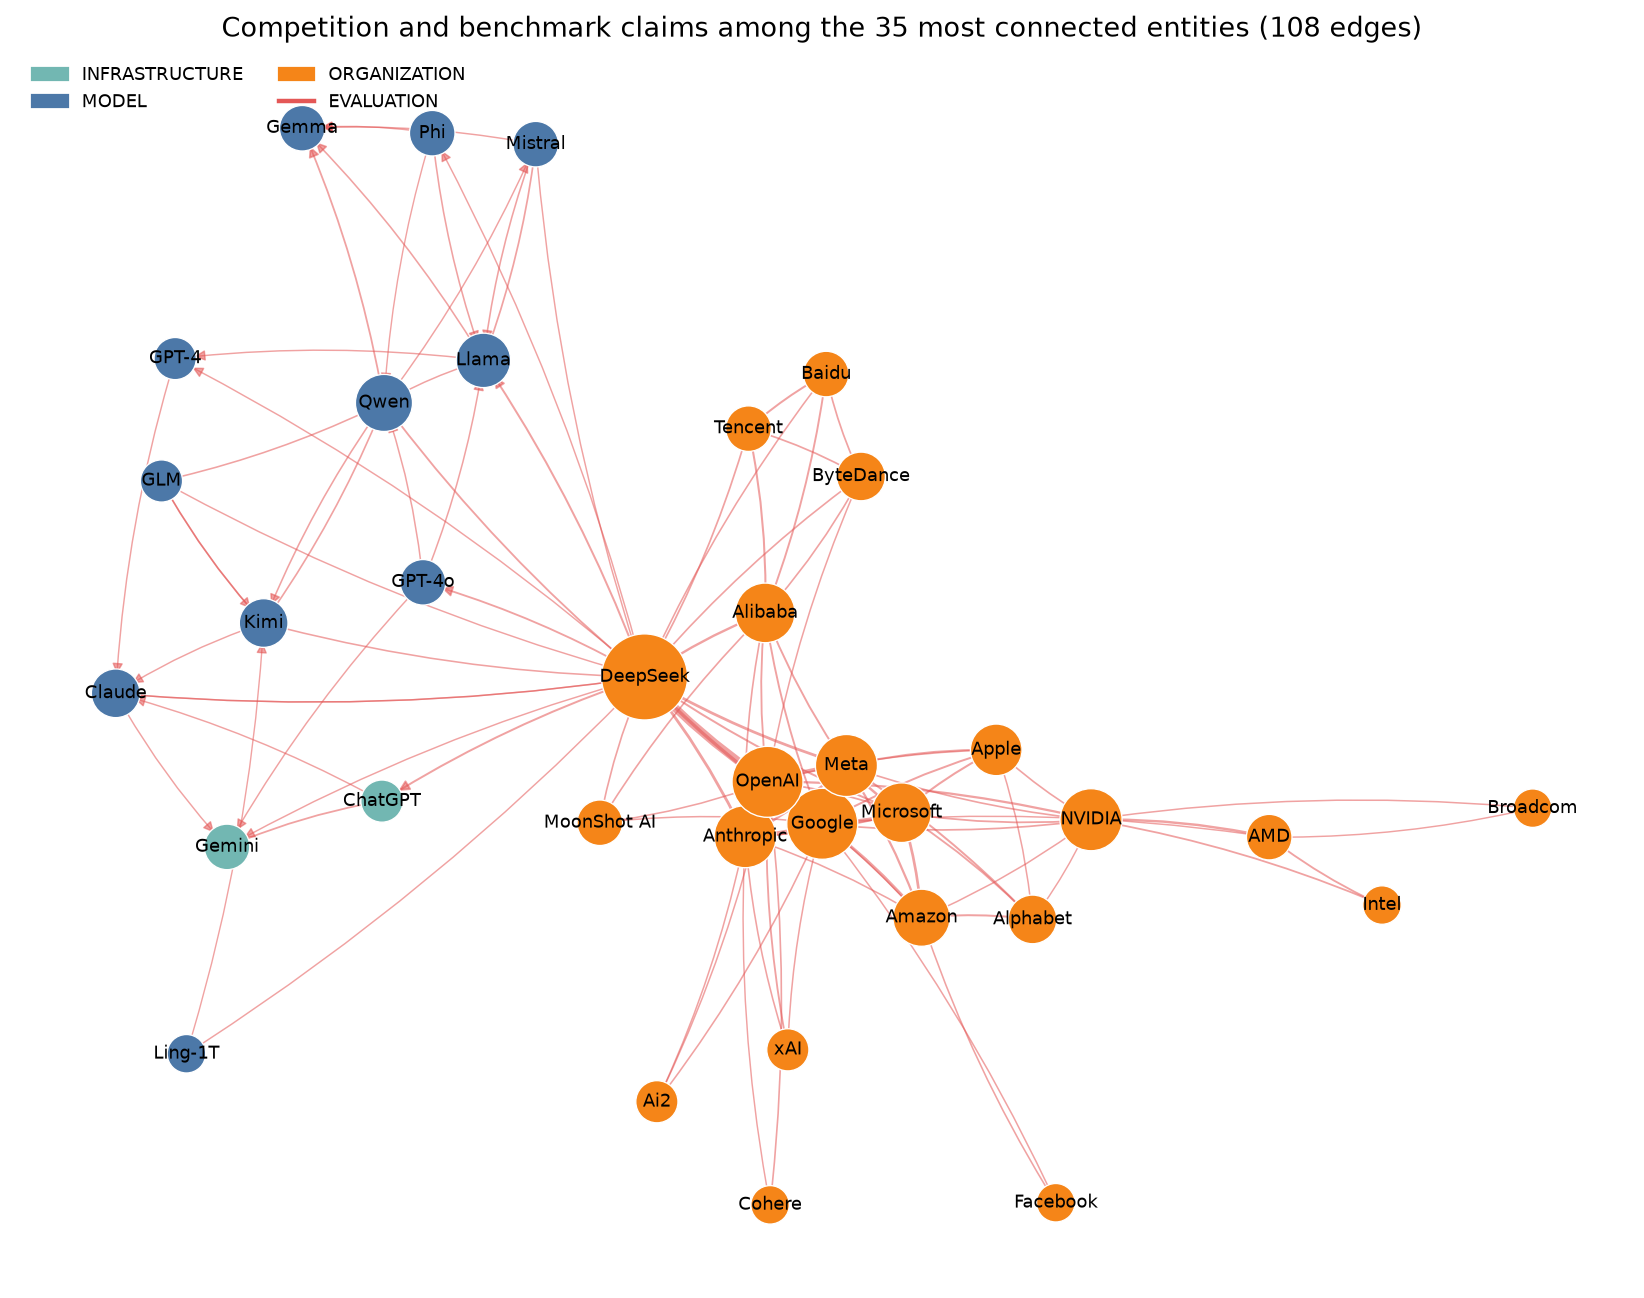

In [22]:
def draw_typed_subgraph(edges, title, filename, max_labels=40, figsize=(14, 10)):
    graph = nx.MultiDiGraph()
    for row in edges.itertuples(index=False):
        for entity_id in (row.subject_id, row.object_id):
            graph.add_node(entity_id, label=labels[entity_id], compact=node_index.loc[entity_id, "entity_type_compact"])
        graph.add_edge(row.subject_id, row.object_id, key=row.predicate, group=row.predicate_group,
                       weight=row.weight, directed=row.directed, sources=row.sources)
    simple = nx.Graph(graph.to_undirected())
    positions = nx.spring_layout(simple, seed=SEED, k=1.6 / np.sqrt(len(simple)), iterations=400)
    fig, ax = plt.subplots(figsize=figsize)
    max_weight = max(d["weight"] for _, _, d in graph.edges(data=True))
    for source, target, data in graph.edges(data=True):
        nx.draw_networkx_edges(graph, positions, edgelist=[(source, target)], ax=ax,
                               width=0.6 + 3.0 * data["weight"] / max_weight,
                               edge_color=GROUP_COLORS.get(data["group"], "#6B7280"), alpha=0.55,
                               style="solid" if "glirel" in data["sources"] else "dashed",
                               arrows=True, arrowstyle="-|>" if data["directed"] else "-", arrowsize=10,
                               connectionstyle="arc3,rad=0.06", node_size=300)
    degree = dict(simple.degree())
    nx.draw_networkx_nodes(graph, positions, ax=ax, linewidths=0.6, edgecolors="white",
                           node_color=[COMPACT_COLORS[graph.nodes[n]["compact"]] for n in graph],
                           node_size=[180 + 60 * degree[n] for n in graph])
    shown = sorted(graph, key=lambda n: -degree[n])[:max_labels]
    nx.draw_networkx_labels(graph, positions, labels={n: pretty(graph.nodes[n]["label"]) for n in shown},
                            font_size=8, ax=ax)
    groups = sorted({d["group"] for _, _, d in graph.edges(data=True)})
    types = sorted({graph.nodes[n]["compact"] for n in graph})
    handles = ([Patch(color=COMPACT_COLORS[t], label=t) for t in types]
               + [Line2D([0], [0], color=GROUP_COLORS[g], lw=2, label=g) for g in groups])
    ax.legend(handles=handles, loc="upper left", frameon=False, fontsize=8, ncol=2)
    ax.set_title(title)
    ax.axis("off")
    save_figure(fig, filename)

core_ids = set(typed_metrics.head(45)["entity_id"])
core_edges = collapsed_analysis[collapsed_analysis["subject_id"].isin(core_ids) & collapsed_analysis["object_id"].isin(core_ids)]
draw_typed_subgraph(core_edges, f"Core typed graph: relations among the 45 highest-PageRank entities ({len(core_edges)} edges)",
                    "06_core_typed_graph.png")

family_ids = set(nodes_kg.loc[nodes_kg["is_open_model_family"], "entity_id"])
family_edges = collapsed[collapsed["subject_id"].isin(family_ids) & collapsed["predicate"].isin(["developed by", "released by"])]
# The figure combines developed by / released by and shows research units with their parent (graph nodes unchanged)
PARENT_ORG = {"org:google_deepmind": "org:google", "org:google_research": "org:google", "org:cohere_labs": "org:cohere",
              "org:microsoft_research": "org:microsoft", "org:ibm_research": "org:ibm", "org:nvidia_research": "org:nvidia",
              "org:fair": "org:meta", "org:meta_superintelligence_labs": "org:meta"}
as_ids = lambda v: v if isinstance(v, (list, tuple, set, np.ndarray)) else json.loads(v)
family_plot = (family_edges.assign(developer=family_edges["object_id"].map(lambda x: PARENT_ORG.get(x, x)))
               .groupby(["subject_id", "developer"])
               .agg(document_count=("document_ids", lambda v: len(set().union(*map(set, map(as_ids, v))))),
                    sources=("sources", lambda v: ";".join(v)),
                    members=("object_id", lambda v: sorted(set(v))))
               .reset_index())
family_plot["pair"] = [
    f"{pretty(labels[s])}  ->  {pretty(labels[d])}"
    + ("" if members == [d] else " (incl. " + ", ".join(pretty(labels[m]) for m in members if m != d) + ")")
    for s, d, members in zip(family_plot["subject_id"], family_plot["developer"], family_plot["members"])]
family_plot["evidence"] = np.select(
    [family_plot["sources"].str.contains("glirel") & family_plot["sources"].str.contains("wp1_lexicon"),
     family_plot["sources"].str.contains("glirel")],
    ["lexicon + article evidence", "article evidence only"], default="lexicon only (no article sentence)")
family_plot = family_plot.sort_values(["document_count", "pair"]).reset_index(drop=True)
EVIDENCE_COLORS = {"lexicon + article evidence": "#4C78A8", "article evidence only": "#F58518",
                   "lexicon only (no article sentence)": "#BAB0AC"}
fig, ax = plt.subplots(figsize=(10, 0.28 * len(family_plot) + 1.5))
ax.barh(family_plot["pair"], family_plot["document_count"].clip(lower=0.3), color=family_plot["evidence"].map(EVIDENCE_COLORS))
for y, value in enumerate(family_plot["document_count"]):
    ax.text(value + 1, y, str(int(value)), va="center", fontsize=7)
ax.legend(handles=[Patch(color=c, label=l) for l, c in EVIDENCE_COLORS.items()], loc="lower right", frameon=False, fontsize=8)
ax.set(title="Open model families -> developer: supporting articles", xlabel="Supporting articles", ylabel="")
ax.tick_params(axis="y", labelsize=8)
save_figure(fig, "07_family_developer_edges.png")

compete = collapsed[collapsed["predicate"].isin(["competes with", "outperforms"])]
compete_ids = set(pd.concat([compete["subject_id"], compete["object_id"]]).value_counts().head(35).index)
compete = compete[compete["subject_id"].isin(compete_ids) & compete["object_id"].isin(compete_ids)]
draw_typed_subgraph(compete, f"Competition and benchmark claims among the 35 most connected entities ({len(compete)} edges)",
                    "08_competition_graph.png", figsize=(13, 10))

## 14. Key findings with evidence

Each finding is based on a graph pattern. The table attaches the number of supporting articles and the
highest-scoring evidence sentence with its publication date, so that every claim can be traced back to the
articles. The relations behind these findings were compared with their evidence sentences (Section 6).

In [23]:
def evidence_example(subject_id, predicate, object_id):
    rows = dated[(dated["subject_id"] == subject_id) & (dated["predicate"] == predicate) & (dated["object_id"] == object_id)]
    rows = rows.sort_values("rule_score", ascending=False).drop_duplicates("document_id").head(1)
    return " ".join(f"[{r.published_at}] {' '.join(str(r.evidence_text).split())[:220]}" for r in rows.itertuples(index=False))

findings = []
developers = relation_metrics[relation_metrics["predicate"] == "developed by"].nlargest(5, "in_degree")
for row in developers.itertuples(index=False):
    products = developed[developed["object_id"] == row.entity_id]
    top = products.nlargest(4, "document_count")
    example = next((e for e in (evidence_example(s, "developed by", row.entity_id) for s in top["subject_id"]) if e), "")
    findings.append({"finding": "developer", "entity or relation": row.canonical_name,
                     "measure": f"developed by in-degree {int(row.in_degree)}", "articles": int(products["document_count"].sum()),
                     "detail": ", ".join(top["subject_id"].map(labels)), "evidence": example})
for row in collapsed[collapsed["predicate"] == "competes with"].nlargest(4, "document_count").itertuples(index=False):
    findings.append({"finding": "competition", "entity or relation": f"{labels[row.subject_id]} -- {labels[row.object_id]}",
                     "measure": "supporting articles", "articles": int(row.document_count),
                     "detail": f"{row.first_seen} to {row.last_seen}",
                     "evidence": evidence_example(row.subject_id, row.predicate, row.object_id)})
for row in shares.nlargest(3, "change_pp").itertuples():
    findings.append({"finding": "rising entity", "entity or relation": row.canonical_name,
                     "measure": f"relation evidence share {row.change_pp:+.1f} pp (P2 - P1)", "articles": None,
                     "detail": row.entity_type_compact, "evidence": ""})
findings = pd.DataFrame(findings)
with pd.option_context("display.max_colwidth", 170):
    display(findings)

,finding,entity or relation,measure,articles,detail,evidence
0,developer,NVIDIA,developed by in-degree 63,273.0,"Nemotron, DGX Spark, NemoClaw, Blackwell architecture",[2025-08-14] NVIDIA-Nemotron-Nano-12B-v2-Base is a large language model (LLM) developed by NVIDIA that is designed as a completion model for a given piece of text.
1,developer,Google,developed by in-degree 51,218.0,"Gemma, Gemini, ML Pathways, TPUs","[2026-06-10] Developed by Google DeepMind, DiffusionGemma undergoes the same rigorous safety evaluations as our proprietary Gemini models."
2,developer,OpenAI,developed by in-degree 42,300.0,"ChatGPT, GPT-5, o1, GPT-4",[2025-03-19] OpenAI has developed ChatGPT into one of the prominent alternatives to Le Chat.
3,developer,Anthropic,developed by in-degree 21,80.0,"Claude, MCP, Sonnet, Claude Code","[2026-03-25] Claude can now use your computer (Activity: 2106): Claude, an AI developed by Anthropic, is now capable of using your computer to perform tasks via Claud..."
4,developer,Meta,developed by in-degree 16,148.0,"Llama, Muse Spark, Behemoth, Maverick",[2026-08-11] Llama is a collection of open models developed by Meta that you can fine-tune and deploy on Gemini Enterprise Agent Platform.
5,competition,DeepSeek -- OpenAI,supporting articles,103.0,2024-12-17 to 2026-08-11,[2024-12-17] DeepSeek said last month that its R1 model competes with OpenAI's o1 — a model designed for reasoning or solving more complex tasks.
6,competition,Anthropic -- OpenAI,supporting articles,97.0,2024-09-25 to 2026-08-27,"[2026-01-15] The company is a public benefit corporation, like OpenAI and competitor Anthropic, which created Claude."
7,competition,Google -- OpenAI,supporting articles,80.0,2024-09-25 to 2026-08-19,"[2025-01-30] This development intensifies the AI-generated media race, placing Google in competition with OpenAI’s Sora and other video synthesis models emerging in t..."
8,competition,Anthropic -- Google,supporting articles,51.0,2024-09-25 to 2026-08-19,"[2026-07-09] Muse Spark 1.1 changes that equation by allowing developers to call Meta’s own hosted infrastructure via the new Meta Model API, putting the company in d..."
9,rising entity,Anthropic,relation evidence share +14.8 pp (P2 - P1),NaN,ORGANIZATION,


In [24]:
developer_mix = {labels[org]: developed[developed["object_id"] == org]["product_type"].value_counts().head(3).to_dict()
                 for org in developers["entity_id"]}
rivals = findings[findings["finding"] == "competition"].head(3)
deepseek = shares.loc["org:deepseek"] if "org:deepseek" in shares.index else None
deepseek_text = (f"DeepSeek's share of relation evidence fell from {deepseek[p1]:.0%} in P1 to {deepseek[p2]:.0%} in P2."
                 if deepseek is not None else "")
SIZE_BINS, SIZE_LABELS = [0, 10, 40, 100, np.inf], ["<=10B", "10-40B", "40-100B", ">100B"]
sized = (model_mentions.drop_duplicates(["head_id", "doc_id"])  # one row per model and article
         .assign(period=lambda d: np.where(d["date"] <= PERIODS[p1][1], p1, p2),
                 size_bin=lambda d: pd.cut(d["parameter_size_b"], SIZE_BINS, labels=SIZE_LABELS)))
size_share = pd.crosstab(sized["period"], sized["size_bin"], normalize="index")
size_docs = sized.groupby("period")["doc_id"].nunique()
family_size_mentions = sized.groupby(["tail", "period"]).size().unstack(fill_value=0)
mid_examples = sized[(sized["period"] == p2) & (sized["size_bin"] == "10-40B")]["head"].value_counts().head(4).index
display(Markdown(f'''
**Findings**

1. **Open-model attention shifted from Llama to Chinese model families and NVIDIA's Nemotron.** Share of Open Models
   articles per quarter ({first_q} -> {last_q}): Llama {fs.loc["Llama", first_q]:.0%} -> {fs.loc["Llama", last_q]:.0%},
   Qwen {fs.loc["Qwen", first_q]:.0%} -> {fs.loc["Qwen", last_q]:.0%}, Kimi {fs.loc["Kimi", first_q]:.0%} -> {fs.loc["Kimi", last_q]:.0%},
   GLM {fs.loc["GLM", first_q]:.0%} -> {fs.loc["GLM", last_q]:.0%}, Nemotron {fs.loc["Nemotron", first_q]:.0%} ->
   {fs.loc["Nemotron", last_q]:.0%} (peak {fs.loc["Nemotron"].max():.0%} in {fs.loc["Nemotron"].idxmax()}; Section 12, Figure 5).
   Mentions show visibility in the media, not usage or quality.
2. **Developers appear with different kinds of artefacts.** Compact types of the `developed by` artefacts:
   {"; ".join(f"{name}: {', '.join(f'{t} {n}' for t, n in mix.items())}" for name, mix in developer_mix.items())}.
   {labels[dev["entity_id"]]} is linked mostly to infrastructure (GPUs, systems, software), while OpenAI, Anthropic and
   Meta are linked mostly to models. Some products appear under several names (Section 10), so these are counts of
   named artefacts in the articles, not of products.
3. **Competition is reported around a few frontier players**: the strongest `competes with` pairs are
   {"; ".join(f"{r['entity or relation']} ({int(r['articles'])} articles)" for _, r in rivals.iterrows())} (Figure 8). The
   counts measure how often the pair is reported as competing, not how strong the competition is.
4. **One quarter shapes the whole graph.** {peak_quarter} contains the most articles and relation evidence.
   {deepseek_text} Centrality over the whole period is therefore strongly influenced by this quarter and is read
   together with the period comparison.
5. **Among open models whose size is part of the name, mid-sized models (10-40B) gained share.** Model mentions with
   a size in the name (one per model and article, Section 5): 10-40B {size_share.loc[p1, "10-40B"]:.0%} ->
   {size_share.loc[p2, "10-40B"]:.0%}, 40-100B {size_share.loc[p1, "40-100B"]:.0%} -> {size_share.loc[p2, "40-100B"]:.0%},
   up to 10B {size_share.loc[p1, "<=10B"]:.0%} -> {size_share.loc[p2, "<=10B"]:.0%}, above 100B {size_share.loc[p1, ">100B"]:.0%} ->
   {size_share.loc[p2, ">100B"]:.0%}. Frequently named 10-40B models in P2: {", ".join(mid_examples)}. By family, Llama
   mentions went from {family_size_mentions.loc["Llama", p1]} to {family_size_mentions.loc["Llama", p2]}, Gemma from
   {family_size_mentions.loc["Gemma", p1]} to {family_size_mentions.loc["Gemma", p2]} and Qwen from
   {family_size_mentions.loc["Qwen", p1]} to {family_size_mentions.loc["Qwen", p2]}: fewer Llama 70B-class mentions and
   more mid-sized Qwen and Gemma models. The sample is small ({size_docs[p1]} -> {size_docs[p2]} articles) and covers
   only models named with a size, so this suggests a shift in what is reported rather than in releases or usage.
'''))


**Findings**

1. **Open-model attention shifted from Llama to Chinese model families and NVIDIA's Nemotron.** Share of Open Models
   articles per quarter (2024Q4 -> 2026Q3): Llama 64% -> 19%,
   Qwen 17% -> 32%, Kimi 0% -> 40%,
   GLM 1% -> 27%, Nemotron 5% ->
   15% (peak 25% in 2026Q1; Section 12, Figure 5).
   Mentions show visibility in the media, not usage or quality.
2. **Developers appear with different kinds of artefacts.** Compact types of the `developed by` artefacts:
   NVIDIA: INFRASTRUCTURE 41, TECHNICAL_COMPONENT 10, MODEL 10; Google: INFRASTRUCTURE 27, MODEL 14, TECHNICAL_COMPONENT 8; OpenAI: MODEL 29, INFRASTRUCTURE 9, TECHNICAL_COMPONENT 3; Anthropic: MODEL 10, INFRASTRUCTURE 8, EVALUATION_RESOURCE 1; Meta: MODEL 10, INFRASTRUCTURE 6.
   NVIDIA is linked mostly to infrastructure (GPUs, systems, software), while OpenAI, Anthropic and
   Meta are linked mostly to models. Some products appear under several names (Section 10), so these are counts of
   named artefacts in the articles, not of products.
3. **Competition is reported around a few frontier players**: the strongest `competes with` pairs are
   DeepSeek -- OpenAI (103 articles); Anthropic -- OpenAI (97 articles); Google -- OpenAI (80 articles) (Figure 8). The
   counts measure how often the pair is reported as competing, not how strong the competition is.
4. **One quarter shapes the whole graph.** 2025Q1 contains the most articles and relation evidence.
   DeepSeek's share of relation evidence fell from 39% in P1 to 11% in P2. Centrality over the whole period is therefore strongly influenced by this quarter and is read
   together with the period comparison.
5. **Among open models whose size is part of the name, mid-sized models (10-40B) gained share.** Model mentions with
   a size in the name (one per model and article, Section 5): 10-40B 21% ->
   37%, 40-100B 21% -> 10%,
   up to 10B 43% -> 38%, above 100B 16% ->
   15%. Frequently named 10-40B models in P2: Qwen3.6-27B, Qwen3.6-35B, gpt-oss-20B, Gemma 4 31B. By family, Llama
   mentions went from 144 to 47, Gemma from
   31 to 64 and Qwen from
   115 to 128: fewer Llama 70B-class mentions and
   more mid-sized Qwen and Gemma models. The sample is small (211 -> 147 articles) and covers
   only models named with a size, so this suggests a shift in what is reported rather than in releases or usage.


## 15. Limitations

- **Errors can remain in unreviewed relations.** Precision of the reviewed sample and the effect of the refinement
  rules are reported in Section 6. Remaining errors are mostly wrong entity links in sentences that list several
  names, and the same kind of error can occur in relations outside the sample. In Stage 3, Tier B relations are
  shown together with their evidence sentences and article dates.
- **Tier A relations have no article sentence.** They come from the curated WP1 lexicon; article-based answers in
  Stage 3 cite Tier B assertions only.
- **Dates are publication dates.** They show when a relation was reported, not when a model was released.
- **Validity over time is not modelled.** A relation records when it was observed (`first_seen`, `last_seen`,
  `published_at` per evidence sentence), not until when it holds. No reporting after `last_seen` does not mean the
  relation ended, and claims such as "largest model" or "best performance" refer to the time of the article. In
  Stage 3, time-sensitive questions filter evidence by date and prefer recent evidence.
- **Co-occurrence is not a semantic relation.** Being mentioned in the same sentence does not imply competition,
  cooperation or causality. Article counts of merged node pairs are upper bounds.
- **Centrality is not industry influence.** The graph describes 1,210 Open Models articles; ranks depend on the
  graph view, weights and thresholds.
- **Rule coverage.** The generic-node rule and the alias table can miss cases (e.g. `Fox`, `Nari`).
- **Family-level grouping.** The WP1 lexicon groups versions into families (`MedGemma` -> `Gemma`, `Mixtral` ->
  `Mistral`), so lineage between versions (`Llama 4 Behemoth` -> `Llama 4 Maverick`) is not represented. Only models
  named with a size (`Qwen3 1.7B`) became separate nodes in Section 5; sizes of other models (`Llama 4 Scout`) and
  context windows are not in the graph.
- **Nodes that are both a company and a model.** WP1 families such as `DeepSeek` that share a name with a company
  receive model relations through role-based typing (Section 5), so one node plays both roles; model relations
  whose endpoint shows `entity_type` COMPANY come from this.
- **Few lineage and training relations.** The single-sentence layer was not used after the review, so relations
  such as `based on`, `distilled from` or `trained on` are rare. Stage 3 answers such questions mainly from
  retrieved evidence sentences.

## 16. Export and re-load check

The graph is stored in formats that Stage 3 and external tools can read:

- **Parquet** (canonical tables) and **CSV** (for inspection);
- **GraphML** (Gephi, Cytoscape; list attributes stored as JSON strings) and **node-link JSON** (NetworkX);
- `graph_schema.json`, `DATA_DICTIONARY.md` and a run manifest with input hashes;
- the correction tables, so that every merged or excluded item can be inspected.

The saved graphs are loaded again and compared with the graphs in memory.

In [25]:
alias_names = nodes.set_index("entity_id")["entity"]
nodes_kg["aliases"] = [
    json.dumps(sorted({alias_names.get(i, "") for i in merged_ids.split(" | ")} - {name, ""}), ensure_ascii=False)
    for merged_ids, name in zip(nodes_kg["merged_ids"], nodes_kg["canonical_name"])
]
graph_node_ids = set(typed_graph) | set(cooccurrence_graph) | set(assertion_graph)
nodes_out = (nodes_kg[nodes_kg["entity_id"].isin(graph_node_ids)]
             .merge(typed_metrics[["entity_id", "pagerank", "betweenness", "weighted_degree"]]
                    .rename(columns=lambda c: c if c == "entity_id" else f"typed_{c}"), on="entity_id", how="left")
             .merge(cooc_metrics[["entity_id", "pagerank", "betweenness", "clustering"]]
                    .rename(columns=lambda c: c if c == "entity_id" else f"cooc_{c}"), on="entity_id", how="left")
             .merge(community_members[["entity_id", "community_id"]], on="entity_id", how="left"))

tables = {
    "nodes": nodes_out,
    "typed_edges_assertions": assertions,
    "typed_edges_collapsed": collapsed,
    "cooccurrence_edges": cooccurrence_edges,
    "node_metrics": pd.concat([typed_metrics, cooc_metrics], ignore_index=True),
    "relation_type_metrics": relation_metrics,
    "relation_type_summary": relation_summary,
    "node_communities": community_members,
    "community_summary": community_summary,
    "quarterly_relation_assertions": quarterly_assertions.reset_index(),
    "quarterly_new_typed_edges": quarterly_new_edges.reset_index(),
    "family_quarterly_share": family_share.reset_index(names="family"),
    "entity_period_share": shares.reset_index(names="entity_id"),
    "relations_first_seen_2026": first_seen_2026,
    "findings": findings,
    "model_name_mentions": model_mentions.drop(columns=["sentence_key"]),
}
for name, table in tables.items():
    table.to_parquet(OUTPUT_DIR / f"{name}.parquet", index=False)
    table.to_csv(OUTPUT_DIR / f"{name}.csv", index=False, encoding="utf-8-sig")

correction_tables = {
    "relations_all_tiers": relations,
    "evidence_status": ev.drop(columns=["sentence_key"]),
    "nodes_corrected": nodes_corrected,
    "name_variants": name_variants,
    "alias_map": pd.DataFrame(ALIAS_MAP, columns=["from_id", "to_id", "note"]),
    "node_overrides": pd.DataFrame(NODE_OVERRIDES, columns=["entity_id", "entity", "entity_type", "note"]),
    "developer_equivalents": pd.DataFrame([(d, e) for d, es in DEVELOPER_EQUIVALENTS.items() for e in es],
                                          columns=["lexicon_developer_id", "accepted_id"]),
    "generic_nodes": nodes_corrected[nodes_corrected["is_generic"]][["entity_id", "entity", "entity_type", "mentions"]],
    "manual_exclusions": manual_exclusions,
}
for name, table in correction_tables.items():
    table.to_csv(OUTPUT_DIR / "correction" / f"{name}.csv", index=False, encoding="utf-8-sig")

def graphml_safe(graph):
    safe = graph.copy()
    for _, data in safe.nodes(data=True):
        data.update({k: scalar(v) for k, v in data.items()})
    edge_data = safe.edges(keys=True, data=True) if safe.is_multigraph() else safe.edges(data=True)
    for *_, data in edge_data:
        data.update({k: scalar(v) for k, v in data.items()})
    return safe

graphs = {"assertion": assertion_graph, "typed": typed_graph, "cooccurrence": cooccurrence_graph}
for name, graph in graphs.items():
    nx.write_graphml(graphml_safe(graph), OUTPUT_DIR / f"{name}_graph.graphml")
    (OUTPUT_DIR / f"{name}_graph.json").write_text(
        json.dumps(nx.node_link_data(graphml_safe(graph), edges="edges"), ensure_ascii=False), encoding="utf-8")

summary = {
    "schema_version": schema_version, "status": GRAPH_STATUS,
    "created_at_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "graphs": {name: graph_summary(graph) for name, graph in graphs.items()},
    "relation_types": int(collapsed["predicate"].nunique()),
    "tiers": collapsed["tier"].value_counts().to_dict(),
    "review": {"labelled_rows": n_reviewed, "true": int(review_counts["TRUE"]), "false": int(review_counts["FALSE"]),
               "ambiguous": int(review_counts["AMBIGUOUS"]),
               "precision": None if np.isnan(review_precision) else round(float(review_precision), 4)},
    "cooccurrence_minimum_articles": MIN_COOCCURRENCE_DOCUMENTS,
    "communities": int(len(community_summary)), "modularity": round(float(modularity), 4),
}
sha256 = lambda path: hashlib.sha256(Path(path).read_bytes()).hexdigest()
manifest = {**summary,
            "inputs": {str(p.relative_to(ROOT)): sha256(p) for p in
                       [WP2_INPUT_DIR / f for f in WP2_FILES]
                       + [LEXICON_PATH, REVIEW_PATH, SUPPLEMENT_REVIEW_PATH, INSIGHT_CHECK_PATH, COMPACT_SCHEMA_PATH]},
            "versions": {"python": sys.version.split()[0], "networkx": nx.__version__, "pandas": pd.__version__}}
for directory in [OUTPUT_DIR, ARTIFACT_DIR]:
    (directory / "graph_schema.json").write_text(json.dumps(graph_schema, ensure_ascii=False, indent=2), encoding="utf-8")
    (directory / "graph_summary.json").write_text(json.dumps(summary, ensure_ascii=False, indent=2), encoding="utf-8")
(OUTPUT_DIR / "run_manifest.json").write_text(json.dumps(manifest, ensure_ascii=False, indent=2), encoding="utf-8")
for name in ["typed_edges_collapsed", "relation_type_summary", "community_summary", "findings"]:
    tables[name].to_csv(ARTIFACT_DIR / f"{name}.csv", index=False, encoding="utf-8-sig")

reloaded = {
    "typed_graph.graphml": ("typed", nx.read_graphml(OUTPUT_DIR / "typed_graph.graphml")),
    "typed_graph.json": ("typed", nx.node_link_graph(json.loads((OUTPUT_DIR / "typed_graph.json").read_text(encoding="utf-8")), edges="edges")),
    "cooccurrence_graph.graphml": ("cooccurrence", nx.read_graphml(OUTPUT_DIR / "cooccurrence_graph.graphml")),
    "assertion_graph.json": ("assertion", nx.node_link_graph(json.loads((OUTPUT_DIR / "assertion_graph.json").read_text(encoding="utf-8")), edges="edges")),
}
reload_check = pd.DataFrame([
    (name, g.number_of_nodes(), g.number_of_edges(),
     (g.number_of_nodes(), g.number_of_edges()) == (graphs[view].number_of_nodes(), graphs[view].number_of_edges()))
    for name, (view, g) in reloaded.items()
], columns=["file", "nodes", "edges", "matches"])
display(reload_check)
assert reload_check["matches"].all()

,file,nodes,edges,matches
0,typed_graph.graphml,856,1010,True
1,typed_graph.json,856,1010,True
2,cooccurrence_graph.graphml,4852,23194,True
3,assertion_graph.json,856,6134,True


In [26]:
DATA_DICTIONARY = f'''# Stage 1 WP3 knowledge graph: data dictionary

Schema `{schema_version}`, review status `{GRAPH_STATUS}`, track Open Models.
All dates (`published_at`, `first_seen`, `last_seen`) are article publication dates.

## Nodes (`nodes.*`)
| column | description |
|---|---|
| `entity_id` | corrected node ID; the WP2 IDs merged into it are listed in `merged_ids` |
| `canonical_name`, `aliases` | display name and merged alternative names (JSON list) |
| `entity_type`, `entity_type_compact` | WP2 entity type and one of the 9 compact types |
| `mention_count`, `document_count` | mentions and articles mentioning the entity |
| `is_open_model_family` | model family from the WP1 lexicon |
| `parameter_sizes_b` | parameter sizes in billions (JSON list): the size in the name for model nodes, the sizes of the member models for family nodes |
| `typed_*`, `cooc_*`, `community_id` | metrics in the typed and co-occurrence graphs, co-occurrence community |

## Typed relations
- `typed_edges_assertions.*`: one row per evidence sentence: `relation_id`, `subject_id`, `predicate`, `object_id`,
  `document_id`, `text_unit_id` (`doc_id:sentence_id`), `evidence_text`, `published_at`, `extraction_method`
  (`glirel`, `wp1_lexicon` or `model_name`), `rule_score`.
- `typed_edges_collapsed.*`: one row per unique triple: `evidence_count`, `document_count` (edge weight),
  `n_distinct_sentences`, `first_seen`, `last_seen`, `tier` (A: lexicon, B: >= 2 distinct sentences, >= 3 for
  `competes with`), `sources`, `added_by` (refinement, role-based typing or model names), `review_status`
  (`reviewed_*` from the random sample, `checked_true_human` / `checked_true_ai` from the findings check),
  `predicate_group`, `directed`, `relation_ids` and `text_unit_ids` (JSON lists).

## Co-occurrence (`cooccurrence_edges.*`)
Entity pairs mentioned in the same sentence in at least {MIN_COOCCURRENCE_DOCUMENTS} articles: `sentence_count`,
`document_count`, `npmi`, `merged_pairs` (original WP2 pairs combined by the refinement). Not a semantic relation.

## Graph files
`assertion_graph`, `typed_graph` and `cooccurrence_graph` as `.graphml` and node-link `.json`.

## Analysis tables
`node_metrics`, `relation_type_metrics`, `relation_type_summary`, `node_communities`, `community_summary`,
`quarterly_relation_assertions`, `quarterly_new_typed_edges`, `family_quarterly_share`, `entity_period_share`,
`relations_first_seen_2026`, `findings`, `model_name_mentions` (sentences behind the model nodes: family, model
node, size, original text `surface`).

## Correction tables (`correction/`)
`relations_all_tiers` (tier and exclusion reason of every relation), `evidence_status`, `nodes_corrected`,
`name_variants`, `alias_map`, `node_overrides`, `developer_equivalents`, `generic_nodes`, `manual_exclusions`.

## Provenance for Stage 3
`entity_id` -> `relation_id` -> `text_unit_id` -> `document_id` -> `published_at`. Article titles and URLs are
joined from the WP1 table `open_models_core.parquet` on `doc_id`.
'''
for directory in [OUTPUT_DIR, ARTIFACT_DIR]:
    (directory / "DATA_DICTIONARY.md").write_text(DATA_DICTIONARY, encoding="utf-8")
print(sorted(p.name for p in ARTIFACT_DIR.iterdir()))

['DATA_DICTIONARY.md', 'community_summary.csv', 'figures', 'findings.csv', 'graph_schema.json', 'graph_summary.json', 'relation_type_summary.csv', 'typed_edges_collapsed.csv']


## 17. Stage 3 retrieval check

The saved graph is loaded with the project's `GraphEvidenceRetriever` to check the path that the graph-enhanced
RAG system will use in Stage 3: entity in the question -> typed relation -> evidence sentence -> article and date.

In [27]:
text_units = pd.DataFrame({"text_unit_id": text_unit(sentences["doc_id"], sentences["sentence_id"]),
                           "document_id": sentences["doc_id"], "text_unit_text": sentences["sentence_text"]})
documents = assertions.dropna(subset=["document_id"]).groupby("document_id")["published_at"].first().reset_index()
if WP1_CORE_PATH.exists():
    documents = documents.merge(pd.read_parquet(WP1_CORE_PATH, columns=["doc_id", "title", "url"])
                                .rename(columns={"doc_id": "document_id"}), on="document_id", how="left")

retriever = GraphEvidenceRetriever(
    nodes=pd.read_parquet(OUTPUT_DIR / "nodes.parquet"),
    assertions=pd.read_parquet(OUTPUT_DIR / "typed_edges_assertions.parquet").dropna(subset=["text_unit_id"]),
    text_units=text_units, documents=documents)
retrieval_rows = []
for query, predicates in [("Who developed Qwen?", ["developed by"]),
                          ("Which companies compete with DeepSeek?", ["competes with"]),
                          ("What does NVIDIA manufacture?", ["manufactured by"])]:
    result = retriever.retrieve(query, predicates=predicates, top_k=3)
    assert result["evidence"], f"no evidence returned for: {query}"
    for item in result["evidence"]:
        retrieval_rows.append({"query": query, "subject": item["subject"]["name"], "predicate": item["predicate"],
                               "object": item["object"]["name"], "published_at": item["published_at"],
                               "document_id": item["document_id"], "passage": str(item["passage"])[:160]})
retrieval_check = pd.DataFrame(retrieval_rows)
with pd.option_context("display.max_colwidth", 160):
    display(retrieval_check)

,query,subject,predicate,object,published_at,document_id,passage
0,Who developed Qwen?,Qwen,developed by,Alibaba,2024-12-03,doc_d95ddd7d2b,"Part of the underlying AI for GeoGPT is Qwen, a large language model built by the Chinese tech company Alibaba."
1,Who developed Qwen?,Qwen,developed by,Alibaba,2025-05-30,doc_3ac75461e8,"Built upon Alibaba’s Qwen3-8B model, this version achieves superior performance on benchmarks like AIME 2025 and HMMT, rivalling models such as Google’s Gem..."
2,Who developed Qwen?,Qwen,developed by,Alibaba,2025-03-31,doc_55f8601c08,"Alibaba Group Holding (BABA Quick QuoteBABA - Free Report) too introduced the QwQ-32B model, an AI system that rivals DeepSeek but requires only a fraction ..."
3,Which companies compete with DeepSeek?,DeepSeek,competes with,OpenAI,2024-12-17,doc_5eb8fa495f,DeepSeek said last month that its R1 model competes with OpenAI's o1 — a model designed for reasoning or solving more complex tasks.
4,Which companies compete with DeepSeek?,DeepSeek,competes with,Google,2026-08-11,doc_6955813d4d,"Models are the most visible products, with close models from firms such as Google, OpenAI, and Anthropic competing against open-weight models from China (e...."
5,Which companies compete with DeepSeek?,DeepSeek,competes with,OpenAI,2026-01-08,doc_be08f0469b,"(AP Photo/Andy Wong, File)\r\n\r\nHONG KONG (AP) — DeepSeek, the Chinese tech startup that rivals OpenAI’s ChatGPT, has been gaining ground in many developi..."
6,What does NVIDIA manufacture?,H100,manufactured by,NVIDIA,2024-11-13,doc_a807f75249,"For certain parts of transformer neural networks such as ChatGPT, Llama2, and Stable Diffusion, the Nvidia H100 and H200 use 8-bit floating point numbers."
7,What does NVIDIA manufacture?,H200,manufactured by,NVIDIA,2024-11-13,doc_a807f75249,"For certain parts of transformer neural networks such as ChatGPT, Llama2, and Stable Diffusion, the Nvidia H100 and H200 use 8-bit floating point numbers."
8,What does NVIDIA manufacture?,RTX 6000 Pro,manufactured by,NVIDIA,2026-03-25,doc_b2d9110022,Daemontatox points out that the issue with NVIDIA’s RTX 6000 Pro being marketed as ‘ Blackwell’ is more related to the Streaming Multiprocessor (SM) archite...


## 18. Requirement check

The Stage 1 *Knowledge Graph Construction* requirements, with the evidence produced in this notebook.

In [28]:
figure_files = sorted(p.name for p in FIGURE_DIR.glob("*.png"))
checked_findings = insight_check["human_checked"].astype(bool) | insight_check["verdict"].eq("TRUE")
requirement_check = pd.DataFrame(
    [
        ("Compact topic-specific schema defined before graph construction", "PASS",
         f"{len(graph_schema['entity_types'])} compact entity types, {len(graph_schema['relation_types'])} relation types, graph_schema.json"),
        ("Nodes are entities, edges are co-mentions or extracted relations", "PASS",
         f"typed {typed_graph.number_of_edges():,} / co-occurrence {cooccurrence_graph.number_of_edges():,} edges"),
        ("Every edge endpoint is in the node table", "PASS" if graph_node_ids <= set(nodes_out["entity_id"]) else "FAIL",
         "nodes.parquet"),
        ("Centrality", "PASS", "weighted degree, PageRank, betweenness, in/out degree per relation type"),
        ("Clustering and communities", "PASS", f"{len(community_summary)} communities, modularity {modularity:.3f}"),
        ("Temporal analysis and emerging relationships", "PASS",
         f"relations and new triples per quarter, family shares, P1 -> P2 change, {len(first_seen_2026)} relations first observed in 2026"),
        ("NetworkX visualisations with legends", "PASS", f"{len(figure_files)} figures"),
        ("Graph and schema stored and re-loaded", "PASS" if reload_check["matches"].all() else "FAIL",
         "GraphML, node-link JSON, Parquet"),
        ("Short schema / data dictionary", "PASS", "DATA_DICTIONARY.md"),
        ("Stage 3 provenance path", "PASS" if len(retrieval_check) else "FAIL", f"{len(retrieval_check)} evidence passages returned"),
        ("Human review of Tier B relations and error analysis",
         "PASS" if GRAPH_STATUS == "human_reviewed_sample" else "PENDING", f"{n_reviewed} / {len(review)} sample rows labelled"),
        ("Relations behind the findings checked against evidence", "PASS",
         f"{int(checked_findings.sum())} of {len(insight_check)} relations, FALSE verdicts confirmed by a person"),
    ],
    columns=["requirement", "status", "evidence"],
)
display(requirement_check)
assert not requirement_check["status"].eq("FAIL").any()

,requirement,status,evidence
0,Compact topic-specific schema defined before g...,PASS,"9 compact entity types, 24 relation types, gra..."
1,"Nodes are entities, edges are co-mentions or e...",PASS,"typed 1,010 / co-occurrence 23,194 edges"
2,Every edge endpoint is in the node table,PASS,nodes.parquet
3,Centrality,PASS,"weighted degree, PageRank, betweenness, in/out..."
4,Clustering and communities,PASS,"193 communities, modularity 0.237"
5,Temporal analysis and emerging relationships,PASS,"relations and new triples per quarter, family ..."
6,NetworkX visualisations with legends,PASS,8 figures
7,Graph and schema stored and re-loaded,PASS,"GraphML, node-link JSON, Parquet"
8,Short schema / data dictionary,PASS,DATA_DICTIONARY.md
9,Stage 3 provenance path,PASS,9 evidence passages returned
